# Text as Data for Economists
## Open-source text classifiers for real problems

**Course material — Universidad del Pacífico, Economics**

Economists increasingly need to turn text into numbers: the tone of a central bank statement, the topic of a consumer complaint, the occupation behind a job ad, the mood of a tweet. This notebook is a toolkit for doing that with **open-source models you can run on your own machine**, without sending data to a paid API.

It is organised around five real problems. Each one introduces a different family of models and a different difficulty you will meet in practice.

| Module | Real problem | Models | What you learn |
|---|---|---|---|
| **1** | Is a central bank sentence hawkish, dovish or neutral? | TF-IDF + logistic regression, **ModernBERT**, **mmBERT** | Fine-tuning an encoder; beating a cheap baseline; what happens when you change language |
| **3** | Route customer banking messages into 77 categories with 8 examples each | **multilingual-E5** embeddings, **SetFit** | Few-shot learning: what to do when labels are expensive |
| **4** | Map free-text job titles to ISCO-08 occupation codes (430+ classes) | Embedding retrieval, k-NN, linear head | Many-class problems; classes you never saw in training; hierarchical evaluation |
| **5** | Sentiment of informal Spanish tweets | **BETO**, **RoBERTuito**, off-the-shelf models | Domain shift: a good model on the wrong kind of text |
| **6** | From classifier to regression | Everything above | Calibration, decision thresholds, and measurement error when a prediction becomes a variable |

Module numbers follow the original course plan (module 2 is not part of this notebook).

### How to use this notebook

* Every module starts with a short **"Before you run"** question. Write your prediction down first. Being wrong about it is the point.
* All datasets ship in the `data/` folder as CSV files. `data/SOURCES.md` lists where each one comes from and its licence.
* Models are downloaded from the Hugging Face Hub the first time you run a cell (roughly 3.5 GB in total), so you need an internet connection for the first run.
* A GPU makes everything fast; a free Colab T4 is enough. On a laptop CPU the notebook switches itself to `FAST_MODE`, which trains on smaller samples so the whole thing finishes in a reasonable time. Results in `FAST_MODE` are noisier and lower; the lessons are the same.

## 0. Setup

Install the libraries once. In Colab, uncomment the line below and run it; on your own machine, `pip install -r requirements.txt` inside a virtual environment is cleaner.

In [1]:
# %pip install -q -r requirements.txt

In [2]:
import math
import os
import random
import re
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.pipeline import make_pipeline
from transformers import (
    AutoConfig,
    AutoModelForSequenceClassification,
    AutoTokenizer,
    get_linear_schedule_with_warmup,
)

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="The number of unique classes")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
pd.set_option("display.max_colwidth", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

### Configuration

Everything you might want to change lives in this one cell.

* `MODELS` holds the Hugging Face identifier of every model used below. To try a different model, change it here.
* `FAST_MODE` shrinks training sets and training time. It turns itself on when no GPU is found. Set it to `False` by hand if you are willing to wait on a CPU.

In [3]:
SEED = 42

MODELS = {
    # English encoder, 149M parameters, 8,192-token context (Warner et al., 2024)
    "modernbert": "answerdotai/ModernBERT-base",
    # Multilingual encoder with the ModernBERT architecture (Marone et al., 2025)
    "multilingual": "jhu-clsp/mmBERT-small",
    # Multilingual sentence-embedding model, 384 dimensions (Wang et al., 2024)
    "embedder": "intfloat/multilingual-e5-small",
    # Spanish BERT trained on Wikipedia, news and other formal text (Cañete et al., 2020)
    "beto": "dccuchile/bert-base-spanish-wwm-cased",
    # Spanish RoBERTa trained on about 500 million tweets (Pérez et al., 2022)
    "robertuito": "pysentimiento/robertuito-base-uncased",
    # Ready-made sentiment classifiers, used without any training
    "sent_tweets": "pysentimiento/robertuito-sentiment-analysis",
    "sent_reviews": "nlptown/bert-base-multilingual-uncased-sentiment",
}

if torch.cuda.is_available():
    DEVICE = "cuda"
elif getattr(torch.backends, "mps", None) is not None and torch.backends.mps.is_available():
    DEVICE = "mps"  # Apple Silicon. If you hit an MPS error, set DEVICE = "cpu".
else:
    DEVICE = "cpu"

FAST_MODE = DEVICE == "cpu"

DATA = Path("data")
if not (DATA / "fomc" / "train.csv").exists():
    # The CSV files normally ship with the notebook. If they are missing,
    # rebuild them from the original public sources on GitHub.
    import runpy

    runpy.run_path("scripts/build_data.py", run_name="__main__")

print(f"device = {DEVICE} | FAST_MODE = {FAST_MODE} | torch {torch.__version__}")

device = cpu | FAST_MODE = True | torch 2.14.1+cpu


### Helper functions

Three small tools are reused in every module.

1. **`finetune`** trains a pretrained encoder as a classifier. It is a plain PyTorch loop, written out so you can see every step: tokenise a batch, run the model, compute the loss, update the weights. In production code you would usually reach for `transformers.Trainer`, which wraps the same loop and adds checkpointing and logging.
2. **`predict_logits`** runs a trained model over a list of texts and returns the raw scores (logits), one column per class.
3. **`score`** records accuracy and macro-F1 in a results table so models can be compared side by side.

**Why macro-F1?** Accuracy rewards a model for getting the most common class right. Macro-F1 is the plain average of the F1 score of each class, so a rare class counts as much as a common one. When classes are unbalanced, and in real data they nearly always are, the two numbers can tell different stories.

In [4]:
def set_seed(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def softmax(logits: np.ndarray) -> np.ndarray:
    z = logits - logits.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)


def load_classifier(model_id: str, labels: list[str]):
    """Load a pretrained encoder with a fresh classification layer on top."""
    config = AutoConfig.from_pretrained(
        model_id,
        num_labels=len(labels),
        id2label=dict(enumerate(labels)),
        label2id={name: i for i, name in enumerate(labels)},
    )
    # ModernBERT can try to compile itself with torch.compile, which fails on
    # some laptops. Turning it off costs a little speed and nothing else.
    if hasattr(config, "reference_compile"):
        config.reference_compile = False
    tokenizer = AutoTokenizer.from_pretrained(model_id)
    model = AutoModelForSequenceClassification.from_pretrained(model_id, config=config)
    return tokenizer, model


def encode_batch(tokenizer, texts: list[str], max_len: int) -> dict:
    enc = tokenizer(texts, padding=True, truncation=True, max_length=max_len, return_tensors="pt")
    return {k: enc[k].to(DEVICE) for k in ("input_ids", "attention_mask")}


def finetune(
    model_id: str,
    texts: list[str],
    y: np.ndarray,
    labels: list[str],
    *,
    epochs: int = 4,
    lr: float = 5e-5,
    batch_size: int = 16,
    max_len: int = 128,
    weight_decay: float = 0.01,
    warmup: float = 0.1,
    class_weights: np.ndarray | None = None,
    seed: int = SEED,
):
    """Fine-tune `model_id` on (texts, y). Returns (tokenizer, model)."""
    set_seed(seed)
    texts = list(texts)
    y = np.asarray(y)
    tokenizer, model = load_classifier(model_id, labels)
    model.to(DEVICE)

    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    steps_per_epoch = math.ceil(len(texts) / batch_size)
    total_steps = epochs * steps_per_epoch
    scheduler = get_linear_schedule_with_warmup(optimizer, int(warmup * total_steps), total_steps)
    weight = None if class_weights is None else torch.tensor(class_weights, dtype=torch.float, device=DEVICE)
    loss_fn = torch.nn.CrossEntropyLoss(weight=weight)

    rng = np.random.default_rng(seed)
    start = time.time()
    for epoch in range(epochs):
        model.train()
        order = rng.permutation(len(texts))
        running = 0.0
        for step in range(steps_per_epoch):
            idx = order[step * batch_size : (step + 1) * batch_size]
            batch = encode_batch(tokenizer, [texts[i] for i in idx], max_len)
            target = torch.tensor(y[idx], dtype=torch.long, device=DEVICE)
            loss = loss_fn(model(**batch).logits, target)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()
            optimizer.zero_grad()
            running += loss.item()
        print(
            f"  epoch {epoch + 1}/{epochs}  mean loss {running / steps_per_epoch:.4f}"
            f"  ({time.time() - start:.0f}s elapsed)"
        )
    model.eval()
    return tokenizer, model


@torch.no_grad()
def predict_logits(tokenizer, model, texts, *, batch_size: int = 64, max_len: int = 128) -> np.ndarray:
    """Raw class scores for each text, as an array of shape (n_texts, n_classes)."""
    texts = list(texts)
    model.to(DEVICE)
    model.eval()
    # Process texts from longest to shortest so each batch needs little padding.
    order = np.argsort([-len(t) for t in texts])
    out = [None] * len(texts)
    for start in range(0, len(texts), batch_size):
        idx = order[start : start + batch_size]
        logits = model(**encode_batch(tokenizer, [texts[i] for i in idx], max_len)).logits
        for i, row in zip(idx, logits.float().cpu().numpy()):
            out[i] = row
    return np.vstack(out)


def free_memory(*models) -> None:
    """Move models off the GPU when a module is finished."""
    for m in models:
        try:
            m.to("cpu")
        except Exception:
            pass
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


RESULTS: list[dict] = []


def score(module: str, model_name: str, y_true, y_pred, **extra) -> dict:
    """Store and return accuracy and macro-F1 for one model on one task."""
    row = {
        "module": module,
        "model": model_name,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
        **extra,
    }
    RESULTS[:] = [r for r in RESULTS if not (r["module"] == module and r["model"] == model_name)]
    RESULTS.append(row)
    print(f"{model_name:<42} accuracy {row['accuracy']:.3f}   macro-F1 {row['macro_f1']:.3f}")
    return row


def results_table(module: str) -> pd.DataFrame:
    df = pd.DataFrame([r for r in RESULTS if r["module"] == module]).drop(columns="module")
    return df.set_index("model").round(3)


def plot_confusion(y_true, y_pred, labels: list[str], title: str, ax=None) -> None:
    """Row-normalised confusion matrix: each row shows where a true class ends up."""
    cm = confusion_matrix(y_true, y_pred, labels=range(len(labels)), normalize="true")
    ax = ax or plt.subplots(figsize=(4.2, 3.8))[1]
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(labels)), labels, rotation=30, ha="right")
    ax.set_yticks(range(len(labels)), labels)
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
    ax.set_title(title, fontsize=10)
    for i in range(len(labels)):
        for j in range(len(labels)):
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center",
                    color="white" if cm[i, j] > 0.5 else "black", fontsize=9)

---
# Module 1 — Central bank tone: hawkish, dovish or neutral?

### The real problem

Markets read every word a central bank publishes. A sentence that hints at higher rates ahead (**hawkish**) moves bond yields differently from one that hints at easing (**dovish**). If you could label every sentence a central bank has ever published, you would have a time series of its *stance*, built from its own words, that you could put on the right-hand side of a regression.

Reading twenty thousand sentences by hand is not feasible. Labelling two thousand and training a model to do the rest is.

### The data

We use the dataset from **Shah, Paturi and Chava (2023), "Trillion Dollar Words"** (ACL 2023). The authors took sentences from US Federal Reserve (FOMC) meeting minutes, press conferences and speeches from 1996 to 2022, and had them labelled by hand as dovish, hawkish or neutral.

* `data/fomc/train.csv` — 1,903 labelled sentences
* `data/fomc/test.csv` — 476 labelled sentences, held out

This is US data in English, not Peruvian data. No public, hand-labelled dataset of this kind exists for the BCRP. That gap is itself a lesson: the last part of this module asks how far an English-trained model can be carried into Spanish, and the closing exercise asks you to label BCRP sentences yourselves.

### The models

1. **TF-IDF + logistic regression.** Count words, weight rare ones more, fit a linear model. Trains in a second. This is the baseline every other model has to beat to justify its cost.
2. **ModernBERT-base.** A 2024 redesign of BERT: faster, trained on more data, and able to read 8,192 tokens at once instead of 512. It is an *encoder*: it reads the whole sentence in both directions and produces a representation that a small classification layer turns into a label. It was trained on English.
3. **mmBERT-small.** The same architecture trained on more than 1,800 languages. We use it to ask what happens when the language changes.

### Before you run

1. A sentence says *"inflation remains elevated"*. Another says *"the Committee will act as appropriate to keep inflation from remaining elevated"*. Which words would a word-counting model rely on, and why might it struggle to separate them?
2. About half of the sentences are neutral. What accuracy does a model get by always answering "neutral"? What macro-F1?
3. Guess the gap in macro-F1 between the TF-IDF baseline and ModernBERT: 2 points, 10 points, 25 points?

In [5]:
FOMC_LABELS = ["dovish", "hawkish", "neutral"]  # label ids 0, 1, 2, as defined by the dataset authors

fomc_train_full = pd.read_csv(DATA / "fomc" / "train.csv")
fomc_test = pd.read_csv(DATA / "fomc" / "test.csv")

# Keep part of the training data aside as a validation set. It is used to make
# choices (here: calibration in Module 6) without ever touching the test set.
fomc_train, fomc_val = train_test_split(
    fomc_train_full, test_size=0.15, stratify=fomc_train_full["label"], random_state=SEED
)
print(f"train {len(fomc_train)}  validation {len(fomc_val)}  test {len(fomc_test)}")
print("\nShare of each label in the training data:")
print(fomc_train["label_name"].value_counts(normalize=True).round(3).to_string())

print("\nTwo examples of each label:")
examples = fomc_train.groupby("label_name").head(2).sort_values("label_name")
for _, r in examples.iterrows():
    print(f"  [{r.label_name:>7}] {r.sentence}")

train 1617  validation 286  test 476

Share of each label in the training data:
label_name
neutral    0.488
dovish     0.262
hawkish    0.250

Two examples of each label:
  [ dovish] What I have elsewhere referred to as "currency competition" may be a driving force behind these changes in inflation outcomes and expectations and may be reflected in low nominal long-term interest rates and the flattening of yield curves.5 I’d like to briefly review what I mean by currency competition.
  [ dovish] In light of the economic outlook, almost all members agreed to indicate that the Committee expects to maintain a highly accommodative stance for monetary policy and currently anticipates that economic conditions--including low rates of resource utilization and a subdued outlook for inflation over the medium run--are likely to warrant exceptionally low levels for the federal funds rate at least through late 2014, longer than had been indicated in recent FOMC statements.
  [hawkish] It is again us

### 1.1 Two baselines

First the laziest possible model (always predict the most common label), then TF-IDF with logistic regression. `class_weight="balanced"` tells the regression to pay more attention to the rarer classes, in proportion to how rare they are.

In [6]:
y_fomc_train = fomc_train["label"].to_numpy()
y_fomc_val = fomc_val["label"].to_numpy()
y_fomc_test = fomc_test["label"].to_numpy()

majority = np.bincount(y_fomc_train).argmax()
score("1 FOMC", f"Always '{FOMC_LABELS[majority]}'", y_fomc_test, np.full_like(y_fomc_test, majority))

fomc_tfidf = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
    LogisticRegression(C=10, max_iter=2000, class_weight="balanced"),
)
fomc_tfidf.fit(fomc_train["sentence"], y_fomc_train)
pred_fomc_tfidf = fomc_tfidf.predict(fomc_test["sentence"])
score("1 FOMC", "TF-IDF + logistic regression", y_fomc_test, pred_fomc_tfidf);

Always 'neutral'                           accuracy 0.473   macro-F1 0.214


TF-IDF + logistic regression               accuracy 0.601   macro-F1 0.580


A linear model on word counts has one great virtue: you can read it. The cell below prints the words and word pairs with the largest coefficients for each class. Check them against your economic intuition. Do they describe *stance*, or just *topic*?

In [7]:
vectorizer, logreg = fomc_tfidf.steps[0][1], fomc_tfidf.steps[1][1]
vocab = np.array(vectorizer.get_feature_names_out())
for k, name in enumerate(FOMC_LABELS):
    top = vocab[np.argsort(logreg.coef_[k])[::-1][:12]]
    print(f"{name:>8}: {', '.join(top)}")

  dovish: lower, accommodative, subdued, down, below, weaker, remains, downside, below percent, accommodative monetary, low, just
 hawkish: higher, up, high, rise in, rise, inflation, pace, solid, stability, supply, increases, ticked
 neutral: between, no, or, appeared, movements, monetary policy, changes in, reserve, countries, gains, changes, monetary


### 1.2 Fine-tuning ModernBERT

**What fine-tuning does.** ModernBERT arrives already knowing a great deal about English, learned by filling in masked words across billions of tokens of text. We add one small layer on top that maps its representation of a sentence to three scores, and then train the whole network for a few passes over our 1,600 labelled sentences. The pretrained weights move only slightly; most of what the model knows was there before we started.

**Choices that matter:**

* **Learning rate.** Too high and the pretrained knowledge is destroyed; too low and nothing is learned. For ModernBERT, values around 5e-5 are a reasonable starting point; for older BERT-style models, 2e-5 to 3e-5.
* **Epochs.** With under two thousand examples, 3 to 5 passes is typical. More usually means memorising the training set.
* **Maximum length.** These are single sentences, so 128 tokens is plenty. Longer limits cost time and memory for nothing here. (ModernBERT's long context matters when you classify whole documents, such as a full set of minutes or a contract.)

In [8]:
if FAST_MODE:
    fomc_fit = fomc_train.groupby("label", group_keys=False).sample(frac=0.4, random_state=SEED)
    FOMC_EPOCHS = 2
else:
    fomc_fit = fomc_train
    FOMC_EPOCHS = 4
print(f"Fine-tuning {MODELS['modernbert']} on {len(fomc_fit)} sentences for {FOMC_EPOCHS} epochs")

fomc_tok, fomc_model = finetune(
    MODELS["modernbert"],
    fomc_fit["sentence"].tolist(),
    fomc_fit["label"].to_numpy(),
    FOMC_LABELS,
    epochs=FOMC_EPOCHS,
    lr=5e-5,
    batch_size=16,
    max_len=128,
)

# Keep the raw scores: Module 6 needs them for calibration.
logits_fomc_val = predict_logits(fomc_tok, fomc_model, fomc_val["sentence"])
logits_fomc_test = predict_logits(fomc_tok, fomc_model, fomc_test["sentence"])
pred_fomc_bert = logits_fomc_test.argmax(axis=1)
score("1 FOMC", "ModernBERT-base (fine-tuned)", y_fomc_test, pred_fomc_bert);

Fine-tuning answerdotai/ModernBERT-base on 647 sentences for 2 epochs


Loading weights:   0%|          | 0/136 [00:00<?, ?it/s]

[transformers] ModernBertForSequenceClassification LOAD REPORT from: answerdotai/ModernBERT-base
Key               | Status     | 
------------------+------------+-
decoder.bias      | UNEXPECTED | 
classifier.bias   | MISSING    | 
classifier.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  epoch 1/2  mean loss 1.0558  (182s elapsed)


  epoch 2/2  mean loss 0.7447  (368s elapsed)


ModernBERT-base (fine-tuned)               accuracy 0.559   macro-F1 0.498


### 1.3 Reading the results

Three things to look at, in this order.

1. **The table.** How large is the gain over the baseline, and is it worth the extra compute for your application? For reference, the dataset's authors report a best F1 of roughly 0.71 with a much larger model (RoBERTa-large). Check their paper for the exact figures and setup before quoting that number.
2. **The confusion matrices.** Each row shows where the sentences of one true class ended up. The economically costly mistake is confusing hawkish with dovish. Confusing either with neutral is milder. Which model makes fewer of the costly mistakes?
3. **The errors themselves.** The last cell prints test sentences the fine-tuned model got wrong with high confidence. Read them. Some will be model failures; some will make you doubt the human label. Both are informative: these sentences were hard for people too, and that puts a ceiling on what any model can score.

,accuracy,macro_f1
model,,
Always 'neutral',0.473,0.214
TF-IDF + logistic regression,0.601,0.580
ModernBERT-base (fine-tuned),0.559,0.498


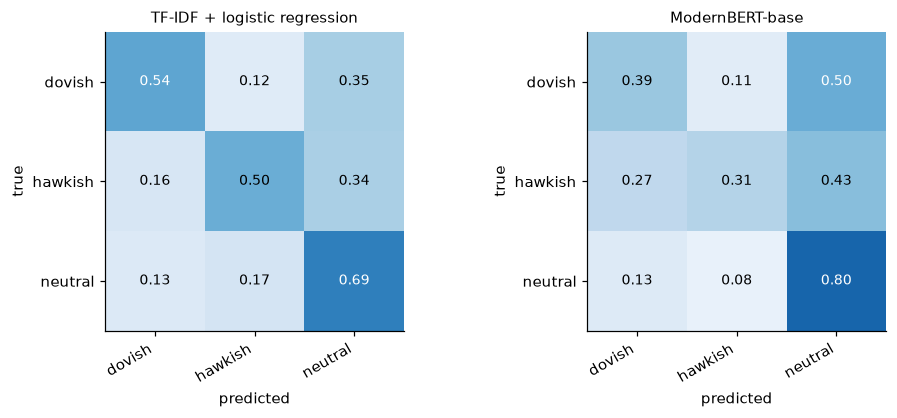

              precision    recall  f1-score   support

      dovish      0.441     0.386     0.412       127
     hawkish      0.551     0.306     0.394       124
     neutral      0.605     0.796     0.687       225

    accuracy                          0.559       476
   macro avg      0.532     0.496     0.498       476
weighted avg      0.547     0.559     0.537       476



In [9]:
display(results_table("1 FOMC"))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.9))
plot_confusion(y_fomc_test, pred_fomc_tfidf, FOMC_LABELS, "TF-IDF + logistic regression", axes[0])
plot_confusion(y_fomc_test, pred_fomc_bert, FOMC_LABELS, "ModernBERT-base", axes[1])
plt.tight_layout()
plt.show()

print(classification_report(y_fomc_test, pred_fomc_bert, target_names=FOMC_LABELS, digits=3))

In [10]:
proba_fomc_test = softmax(logits_fomc_test)
errors = fomc_test.assign(
    predicted=[FOMC_LABELS[i] for i in pred_fomc_bert],
    confidence=proba_fomc_test.max(axis=1).round(3),
)
errors = errors[errors["predicted"] != errors["label_name"]].sort_values("confidence", ascending=False)
print(f"{len(errors)} errors out of {len(fomc_test)} test sentences. The most confident ones:")
display(errors[["sentence", "label_name", "predicted", "confidence"]].head(8))

210 errors out of 476 test sentences. The most confident ones:


,sentence,label_name,predicted,confidence
404,The Committee will regularly review the size and composition of its securities holdings in light of incoming information and is prepared to adjust those hol...,dovish,neutral,0.903
256,"In determining how long to maintain a highly accommodative stance of monetary policy, the Committee will also consider other information, including addition...",dovish,neutral,0.854
177,"Now with respect to the first objective, the rationale for maximizing employment is fairly obvious.",dovish,neutral,0.843
151,"Yet, with a few exceptions, the available data show that productivity growth in other advanced countries has not increased to the extent seen in the United ...",dovish,neutral,0.823
19,Staff Economic Outlook The projection for U. S. economic activity prepared by the staff for the April–May FOMC meeting was revised up on net.,hawkish,neutral,0.784
278,That's why I said that flexibility is also an important characteristic of monetary policy during a time of financial turmoil.,dovish,neutral,0.767
293,"In contrast, some other participants judged that the economy had not yet reached maximum employment.",dovish,neutral,0.726
157,Participants expected economic activity to contract sharply in the fourth quarter of 2008 and in early 2009.,dovish,neutral,0.723


### 1.4 Changing language: from the Fed to the BCRP

Suppose you want the same index for Peru. You have no labelled Spanish sentences. There are three options:

1. Translate BCRP text to English and use the English model.
2. Label a few hundred Spanish sentences and fine-tune a Spanish model.
3. Train a **multilingual** model on the English labels and apply it directly to Spanish. This is called *zero-shot cross-lingual transfer*. It works when the model maps sentences with the same meaning in different languages to nearby representations.

The cell below tries option 3 with mmBERT-small, trained on exactly the same English sentences as before.

**Before you run:** ModernBERT was trained on English only. If you give it a Spanish sentence, will it fail completely, do about as well as chance, or do surprisingly well? Why might central bank Spanish be easier for it than everyday Spanish?

**About the Spanish sentences below.** They were written for this class in the style of central bank communication, each paired with an English version of the same meaning. They are **not quotations** from the BCRP or anyone else, and six sentences are a demonstration, not an evaluation. The exercise at the end of the module replaces them with real ones.

In [11]:
print(f"Fine-tuning {MODELS['multilingual']} on the same English sentences")
ml_tok, ml_model = finetune(
    MODELS["multilingual"],
    fomc_fit["sentence"].tolist(),
    fomc_fit["label"].to_numpy(),
    FOMC_LABELS,
    epochs=FOMC_EPOCHS,
    lr=5e-5,
    batch_size=16,
    max_len=128,
)
pred_fomc_ml = predict_logits(ml_tok, ml_model, fomc_test["sentence"]).argmax(axis=1)
score("1 FOMC", "mmBERT-small (fine-tuned)", y_fomc_test, pred_fomc_ml);

Fine-tuning jhu-clsp/mmBERT-small on the same English sentences


Loading weights:   0%|          | 0/136 [00:00<?, ?it/s]

[transformers] ModernBertForSequenceClassification LOAD REPORT from: jhu-clsp/mmBERT-small
Key               | Status     | 
------------------+------------+-
decoder.bias      | UNEXPECTED | 
decoder.weight    | UNEXPECTED | 
classifier.bias   | MISSING    | 
classifier.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  epoch 1/2  mean loss 1.5379  (97s elapsed)


  epoch 2/2  mean loss 0.7614  (193s elapsed)


mmBERT-small (fine-tuned)                  accuracy 0.511   macro-F1 0.417


In [12]:
# Illustrative sentences written for this class. Not quotations.
parallel = pd.DataFrame(
    [
        ("hawkish",
         "El Directorio acordó elevar la tasa de interés de referencia en 25 puntos básicos ante el aumento de las expectativas de inflación.",
         "The Board agreed to raise the reference interest rate by 25 basis points in response to rising inflation expectations."),
        ("hawkish",
         "Las presiones inflacionarias persisten y podrían requerir ajustes adicionales en la posición de política monetaria.",
         "Inflationary pressures persist and may require further adjustments to the monetary policy stance."),
        ("dovish",
         "El Directorio decidió reducir la tasa de interés de referencia en 25 puntos básicos, dado que la inflación retornó al rango meta.",
         "The Board decided to lower the reference interest rate by 25 basis points, as inflation has returned to the target range."),
        ("dovish",
         "La actividad económica muestra señales de debilidad y la inflación sin alimentos y energía continúa disminuyendo.",
         "Economic activity shows signs of weakness and inflation excluding food and energy continues to decline."),
        ("neutral",
         "El Directorio se reunirá nuevamente el próximo mes para evaluar la información disponible.",
         "The Board will meet again next month to assess the available information."),
        ("neutral",
         "El informe describe la evolución de los principales indicadores durante el trimestre.",
         "The report describes the evolution of the main indicators during the quarter."),
    ],
    columns=["expected", "spanish", "english"],
)


def label_names(tok, model, texts):
    return [FOMC_LABELS[i] for i in predict_logits(tok, model, texts).argmax(axis=1)]


transfer = parallel[["expected"]].copy()
transfer["ModernBERT / English"] = label_names(fomc_tok, fomc_model, parallel["english"])
transfer["ModernBERT / Spanish"] = label_names(fomc_tok, fomc_model, parallel["spanish"])
transfer["mmBERT / English"] = label_names(ml_tok, ml_model, parallel["english"])
transfer["mmBERT / Spanish"] = label_names(ml_tok, ml_model, parallel["spanish"])
display(transfer)
print("Sentences labelled as expected, out of", len(parallel))
print(transfer.drop(columns="expected").eq(transfer["expected"], axis=0).sum().to_string())

free_memory(ml_model)

,expected,ModernBERT / English,ModernBERT / Spanish,mmBERT / English,mmBERT / Spanish
0,hawkish,hawkish,neutral,hawkish,neutral
1,hawkish,neutral,neutral,neutral,neutral
2,dovish,hawkish,neutral,hawkish,neutral
3,dovish,dovish,neutral,neutral,neutral
4,neutral,neutral,neutral,neutral,neutral
5,neutral,neutral,neutral,neutral,neutral


Sentences labelled as expected, out of 6
ModernBERT / English    4
ModernBERT / Spanish    2
mmBERT / English        3
mmBERT / Spanish        2


### What to take from Module 1

* **Always fit the cheap baseline first.** It tells you how hard the task is and gives the expensive model a number to beat. If TF-IDF is within a couple of points, you may not need a neural network at all.
* **Model choice depends on language.** ModernBERT is an English model. For Spanish you need a multilingual model (mmBERT, XLM-RoBERTa) or a Spanish one (BETO, RoBERTuito, which appear in Module 5).
* **Cross-lingual transfer is an empirical question.** It can work well on formal, technical text and badly elsewhere. Six sentences prove nothing either way. The only way to know is to label a test set in the target language.
* **Human labels have noise.** On a subjective task, no model can reliably beat the level of agreement between the annotators.

### Exercises

1. **Seeds.** Fine-tune ModernBERT three times with `seed=1, 2, 3`. How much does macro-F1 move? Is the gap to the baseline larger than that movement?
2. **Class weights.** Pass `class_weights` to `finetune` (inverse class frequencies). Does recall on hawkish and dovish improve? What happens to neutral?
3. **A BCRP test set.** Take one *Nota Informativa del Programa Monetario* from the BCRP website. Split it into sentences. Have two people label each sentence independently, then compute how often they agree. Apply the mmBERT model and compare. Which is higher, human–human agreement or model–human agreement?
4. **Model size.** Change `MODELS["multilingual"]` to `"jhu-clsp/mmBERT-base"` and repeat 1.4. Does a larger multilingual model transfer better?

---
# Module 3 — Few-shot learning: routing customer messages with 8 examples per class

### The real problem

A bank, a telecom operator or a regulator receives thousands of free-text messages a day. Each has to reach the right team: card problems, transfers, fees, fraud. A consumer-protection agency such as Indecopi, or a financial regulator such as the SBS, faces the same task with complaints.

Module 1 had about 1,600 labelled sentences for 3 classes. Here there are **77 categories**. Labelling 500 examples of each would mean 38,500 hand-labelled messages. Nobody has that budget at the start of a project. What you realistically have is an afternoon and a handful of examples per category.

### The data

**Banking77** (Casanueva et al., 2020): 13,083 real customer-service queries sent to an online bank, each labelled with one of 77 intents. It is in English and is not a complaints dataset in the regulatory sense; it is the closest openly licensed dataset to the routing problem. The embedding model used below is multilingual, so the same code runs on Spanish text.

We **pretend to be poor**: we sample 8 examples per class (616 messages) to train on, and keep the remaining labels only to measure how much we lose.

### The models

* **Sentence embeddings (multilingual-E5-small).** A model trained so that texts with similar meaning land close together in a 384-dimensional space. We use it *frozen*: turn each message into a vector once, then fit a logistic regression on those vectors. Nothing in the neural network is trained.
* **SetFit** (Tunstall et al., 2022). Takes the same embedding model and *adapts* it to the task before fitting the classifier. It builds pairs of training examples (same class: pull together; different class: push apart) and fine-tunes the embedding model on those pairs. With 616 examples there are about 190,000 possible pairs, which is how a small labelled set becomes enough training signal.

### Before you run

1. With 8 examples per class, will TF-IDF + logistic regression be closer to 20%, 50% or 80% accuracy over 77 classes? (Chance is 1.3%.)
2. A frozen embedding model has never seen this bank's categories. Why might it still do well?
3. How many examples per class do you think the embedding approach needs to match TF-IDF trained on **all** 10,000 examples?

In [13]:
from sentence_transformers import SentenceTransformer

b77_train = pd.read_csv(DATA / "banking77" / "train.csv")
b77_test = pd.read_csv(DATA / "banking77" / "test.csv")
if FAST_MODE:
    # Shuffle, then keep the first rows of each class (some classes have only 35 training examples).
    b77_train = b77_train.sample(frac=1, random_state=SEED).groupby("label").head(35)
    b77_test = b77_test.sample(frac=1, random_state=SEED).groupby("label").head(12)
b77_train, b77_test = b77_train.reset_index(drop=True), b77_test.reset_index(drop=True)

B77_LABELS = sorted(b77_train["label"].unique())
b77_id = {name: i for i, name in enumerate(B77_LABELS)}
y_b77_train = b77_train["label"].map(b77_id).to_numpy()
y_b77_test = b77_test["label"].map(b77_id).to_numpy()

print(f"{len(B77_LABELS)} classes | train pool {len(b77_train)} | test {len(b77_test)}")
display(b77_train.sample(6, random_state=1))

77 classes | train pool 2695 | test 924


,text,label
2604,Why am I unable to verify my id?,unable_to_verify_identity
1777,Is my new card activated?,activate_my_card
429,Whats the maximum disposable virtual cards?,disposable_card_limits
1490,Top up is not working even though I have my AMEX in apple pay.,apple_pay_or_google_pay
1636,how come my transfer declined,declined_transfer
415,"I want to top up my account by a bank transfer, but will I be charged?",top_up_by_bank_transfer_charge


### 3.1 Turning text into vectors

`embed` returns one row per text. Two details matter.

* **The prefix.** E5 models were trained with every input starting with `"query: "` or `"passage: "`, and they expect the same at inference time. For classification and similarity, use `"query: "` on everything. Forgetting the prefix does not raise an error; it only makes the results quietly worse. Always read the model card.
* **Normalisation.** Vectors are scaled to length 1, so the dot product of two vectors is their cosine similarity.

We embed the whole training pool once and reuse the vectors in every experiment below. That is what makes the few-shot experiments cheap.

In [14]:
embedder = SentenceTransformer(MODELS["embedder"], device=DEVICE)


def embed(texts, prefix: str = "query: ", batch_size: int = 64) -> np.ndarray:
    return embedder.encode(
        [prefix + str(t) for t in texts],
        batch_size=batch_size,
        normalize_embeddings=True,
        convert_to_numpy=True,
        show_progress_bar=len(texts) > 2000,
    )


E_b77_train = embed(b77_train["text"])
E_b77_test = embed(b77_test["text"])
print("embedding matrix:", E_b77_train.shape)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batches:   0%|          | 0/43 [00:00<?, ?it/s]

embedding matrix: (2695, 384)


### 3.2 Eight examples per class

`sample_k` draws `k` examples from each class. Everything else in the training pool is treated as if it had never been labelled.

In [15]:
K_SHOT = 8


def sample_k(k: int, seed: int) -> np.ndarray:
    """Row positions of k training examples per class."""
    rng = np.random.default_rng(seed)
    return np.concatenate(
        [rng.choice(np.flatnonzero(y_b77_train == c), size=k, replace=False) for c in range(len(B77_LABELS))]
    )


def fit_tfidf(idx):
    model = make_pipeline(
        TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True),
        LogisticRegression(C=20, max_iter=3000),
    )
    return model.fit(b77_train["text"].iloc[idx], y_b77_train[idx])


def fit_head(idx):
    """Logistic regression on frozen embeddings."""
    return LogisticRegression(C=20, max_iter=3000).fit(E_b77_train[idx], y_b77_train[idx])


few_idx = sample_k(K_SHOT, SEED)
all_idx = np.arange(len(b77_train))
print(f"few-shot training set: {len(few_idx)} messages")

score("3 Banking77", f"TF-IDF + LR, {K_SHOT} per class", y_b77_test, fit_tfidf(few_idx).predict(b77_test["text"]))
score("3 Banking77", f"Frozen E5 + LR, {K_SHOT} per class", y_b77_test, fit_head(few_idx).predict(E_b77_test));

few-shot training set: 616 messages


TF-IDF + LR, 8 per class                   accuracy 0.656   macro-F1 0.651


Frozen E5 + LR, 8 per class                accuracy 0.802   macro-F1 0.798


### 3.3 SetFit: adapting the embedding model

The frozen model placed messages by *general* meaning. Two messages about cards are close to each other whether they concern a lost card or a declined payment, and our categories need those kept apart. SetFit moves the embedding space so that the distinctions that matter for **this** task become the large ones.

`max_steps` caps the number of training steps. With 77 classes there are far more pairs than we need, and the gains flatten out early.

In [16]:
from datasets import Dataset
from setfit import SetFitModel
from setfit import Trainer as SetFitTrainer
from setfit import TrainingArguments as SetFitArguments

SETFIT_STEPS = 150 if FAST_MODE else 1200

few_ds = Dataset.from_dict(
    {
        "text": ["query: " + t for t in b77_train["text"].iloc[few_idx]],
        "label": y_b77_train[few_idx].tolist(),
    }
)

set_seed()
setfit_model = SetFitModel.from_pretrained(MODELS["embedder"])
setfit_model.to(DEVICE)
setfit_args = SetFitArguments(
    output_dir="outputs/setfit",
    batch_size=16,
    num_epochs=1,
    max_steps=SETFIT_STEPS,
    sampling_strategy="oversampling",
    report_to="none",
    save_strategy="no",
    seed=SEED,
)
setfit_trainer = SetFitTrainer(model=setfit_model, args=setfit_args, train_dataset=few_ds)
setfit_trainer.train()

b77_test_prefixed = ["query: " + t for t in b77_test["text"]]
pred_b77_setfit = np.asarray(setfit_model.predict(b77_test_prefixed, as_numpy=True)).astype(int)
score("3 Banking77", f"SetFit, {K_SHOT} per class", y_b77_test, pred_b77_setfit);

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

model_head.pkl not found on HuggingFace Hub, initialising classification head with random weights. You should TRAIN this model on a downstream task to use it for predictions and inference.


Map:   0%|          | 0/616 [00:00<?, ? examples/s]

***** Running training *****


  Num unique pairs = 2400


...

  Num epochs = 1


[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 2, 'bos_token_id': 0, 'pad_token_id': 1}.


D:\Cursos Dictado\Data Science\2026-II\Classifier Models\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Step,Training Loss
1,0.228156
50,0.207981
100,0.095632
150,0.095635


SetFit, 8 per class                        accuracy 0.737   macro-F1 0.725


### 3.4 What would more labels have bought?

Two reference points, using **every** label in the training pool. These are the numbers you would get with the labelling budget you do not have.

In [17]:
tfidf_full = fit_tfidf(all_idx)
head_full = fit_head(all_idx)
score("3 Banking77", "TF-IDF + LR, all labels", y_b77_test, tfidf_full.predict(b77_test["text"]))
score("3 Banking77", "Frozen E5 + LR, all labels", y_b77_test, head_full.predict(E_b77_test))
display(results_table("3 Banking77"))

TF-IDF + LR, all labels                    accuracy 0.838   macro-F1 0.834
Frozen E5 + LR, all labels                 accuracy 0.877   macro-F1 0.875


,accuracy,macro_f1
model,,
"TF-IDF + LR, 8 per class",0.656,0.651
"Frozen E5 + LR, 8 per class",0.802,0.798
"SetFit, 8 per class",0.737,0.725
"TF-IDF + LR, all labels",0.838,0.834
"Frozen E5 + LR, all labels",0.877,0.875


### 3.5 The learning curve: how much is one more label worth?

This is the plot to bring to a budget meeting. The horizontal axis is the number of labelled examples per class; the vertical axis is accuracy on the test set. Each point is the average over three random draws of the training examples, and the shaded band shows the spread between draws.

Look for two things: the **gap** between the curves at small `k`, and the point where each curve **flattens**. Where a curve is flat, more labelling buys little.

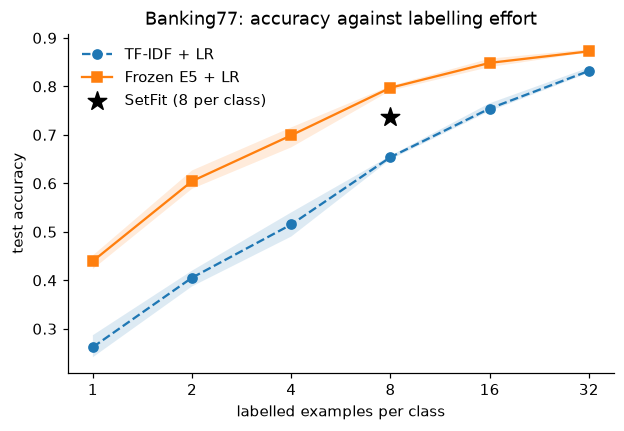

In [18]:
shots = [1, 2, 4, 8, 16, 32]
max_k = int(np.bincount(y_b77_train).min())
shots = [k for k in shots if k <= max_k]
draws = [0, 1, 2]

curve = []
for k in shots:
    for seed in draws:
        idx = sample_k(k, seed)
        curve.append({"k": k, "method": "TF-IDF + LR",
                      "accuracy": accuracy_score(y_b77_test, fit_tfidf(idx).predict(b77_test["text"]))})
        curve.append({"k": k, "method": "Frozen E5 + LR",
                      "accuracy": accuracy_score(y_b77_test, fit_head(idx).predict(E_b77_test))})
curve = pd.DataFrame(curve)

fig, ax = plt.subplots(figsize=(6.4, 4))
for method, style in [("TF-IDF + LR", "o--"), ("Frozen E5 + LR", "s-")]:
    stats = curve[curve["method"] == method].groupby("k")["accuracy"].agg(["mean", "min", "max"])
    ax.plot(stats.index, stats["mean"], style, label=method)
    ax.fill_between(stats.index, stats["min"], stats["max"], alpha=0.15)
ax.scatter([K_SHOT], [accuracy_score(y_b77_test, pred_b77_setfit)], marker="*", s=160, color="black",
           zorder=3, label=f"SetFit ({K_SHOT} per class)")
ax.set_xscale("log", base=2)
ax.set_xticks(shots, [str(k) for k in shots])
ax.set_xlabel("labelled examples per class")
ax.set_ylabel("test accuracy")
ax.set_title("Banking77: accuracy against labelling effort")
ax.legend(frameon=False)
plt.show()

### 3.6 Which categories get confused?

An overall accuracy hides the operational question: *which* messages go to the wrong team? The cell lists the pairs of categories most often confused by the few-shot SetFit model.

Read the list as a manager would. Some pairs are two names for nearly the same thing, and the cheapest fix is to merge the categories. Others are different problems that happen to share vocabulary, and the fix is a few more labelled examples of exactly those two.

In [19]:
cm = confusion_matrix(y_b77_test, pred_b77_setfit, labels=range(len(B77_LABELS)))
np.fill_diagonal(cm, 0)
pairs = [
    {"true category": B77_LABELS[i], "sent to": B77_LABELS[j], "messages": int(cm[i, j])}
    for i, j in zip(*np.unravel_index(np.argsort(cm, axis=None)[::-1][:10], cm.shape))
    if cm[i, j] > 0
]
display(pd.DataFrame(pairs))

per_class = pd.Series(
    f1_score(y_b77_test, pred_b77_setfit, average=None, labels=range(len(B77_LABELS))), index=B77_LABELS
)
print("Five hardest categories (F1):")
print(per_class.sort_values().head(5).round(2).to_string())

,true category,sent to,messages
0,reverted_card_payment?,declined_card_payment,7
1,virtual_card_not_working,get_disposable_virtual_card,5
2,verify_my_identity,why_verify_identity,5
3,supported_cards_and_currencies,fiat_currency_support,5
4,top_up_reverted,top_up_failed,5
5,automatic_top_up,top_up_limits,5
6,order_physical_card,card_payment_fee_charged,4
7,pending_transfer,failed_transfer,4
8,beneficiary_not_allowed,failed_transfer,4
9,balance_not_updated_after_bank_transfer,failed_transfer,3


Five hardest categories (F1):
supported_cards_and_currencies    0.15
declined_cash_withdrawal          0.24
top_up_reverted                   0.25
pending_cash_withdrawal           0.35
reverted_card_payment?            0.42


### 3.7 Does it carry over to Spanish?

The classifier was trained only on English messages, but the embedding model is multilingual. If Spanish and English messages with the same meaning land in the same region of the embedding space, the English-trained classifier should route Spanish messages too.

The Spanish messages below were written for this class as plausible examples. As in Module 1, a handful of sentences is a demonstration, not a measurement.

In [20]:
spanish_messages = [
    "Pedí mi tarjeta hace dos semanas y todavía no llega.",
    "Me cobraron dos veces la misma compra.",
    "¿Qué tipo de cambio aplican cuando pago en dólares?",
    "Creo que alguien usó mi tarjeta sin mi permiso.",
    "¿Cómo cambio la clave de mi tarjeta?",
    "Hice una transferencia ayer y el dinero no aparece en la otra cuenta.",
]
proba_es = head_full.predict_proba(embed(spanish_messages))
top = proba_es.argmax(axis=1)
display(
    pd.DataFrame(
        {
            "message": spanish_messages,
            "predicted category": [B77_LABELS[head_full.classes_[i]] for i in top],
            "probability": proba_es.max(axis=1).round(2),
        }
    )
)

,message,predicted category,probability
0,Pedí mi tarjeta hace dos semanas y todavía no llega.,card_arrival,0.32
1,Me cobraron dos veces la misma compra.,transaction_charged_twice,0.85
2,¿Qué tipo de cambio aplican cuando pago en dólares?,supported_cards_and_currencies,0.24
3,Creo que alguien usó mi tarjeta sin mi permiso.,compromised_card,0.61
4,¿Cómo cambio la clave de mi tarjeta?,change_pin,0.18
5,Hice una transferencia ayer y el dinero no aparece en la otra cuenta.,transfer_not_received_by_recipient,0.33


In [21]:
# Probabilities on the test set from the full-data classifier. Module 6 uses them.
proba_b77_test = head_full.predict_proba(E_b77_test)
free_memory(setfit_model)

### What to take from Module 3

* **Labels are the binding constraint, not models.** Before asking "which model?", ask "how many labels can I afford, and what does each additional one buy?" The learning curve answers that.
* **Pretrained embeddings carry most of the load when labels are few.** Word counts have to learn the meaning of every word from your examples. Embeddings arrive already knowing it.
* **Adapting the embeddings (SetFit) helps most in exactly the low-label regime.** With thousands of labels per class, ordinary fine-tuning as in Module 1 is the simpler choice.
* **Read the confusions, not only the accuracy.** Category definitions are a design choice, and often the cheapest improvement is to fix them.

### Exercises

1. **Which eight?** Rerun 3.2 with five different seeds for `sample_k`. How far apart are the best and worst draws? What does that say about reporting one few-shot number?
2. **Without the prefix.** Change the prefix in `embed` to `""` and rerun 3.2. How much accuracy does a forgotten prefix cost?
3. **A complaints taxonomy for Peru.** Write 8 example complaints in Spanish for each of 6 categories a regulator might use (fees, unrecognised charges, insurance, pension funds, debt collection, customer service). Train the frozen-embedding classifier on them and try it on 20 new complaints you write. Where does it fail?
4. **Active learning.** Instead of sampling at random, start from 2 examples per class, then repeatedly label the 77 messages the classifier is least sure about. Does the curve rise faster than random sampling?

---
# Module 4 — Hundreds of classes: mapping job titles to occupation codes

### The real problem

Labour economists need occupations coded to a standard classification. Household surveys record what people say they do in their own words (*"chofer de combi"*, *"asistente contable"*, *"vendo ropa en Gamarra"*), and online job ads use whatever title the employer chose. To study wages, informality or exposure to automation by occupation, each of those strings has to become a code in **ISCO-08**, the international classification maintained by the ILO. Its Spanish version is called CIUO-08, and national statistical offices including INEI build their own classifiers on it.

Statistical offices have traditionally done this with trained human coders. It is slow, expensive, and two coders often disagree.

Two things make this harder than the earlier modules:

* **Scale.** ISCO-08 has 436 unit groups at its most detailed (4-digit) level. Many have very few examples.
* **Structure.** The codes form a tree. `2411` (Accountants) and `2412` (Financial and investment advisers) share their first three digits. Confusing them is a small error. Confusing `2411` with `9112` (Cleaners) is a large one. A single accuracy number treats both the same.

### The data

**ESCO** is the European Commission's occupation taxonomy. It lists 3,007 detailed occupations, each mapped to an ISCO-08 unit group, with a preferred title, a description and a list of alternative titles: about 32,000 distinct job titles in total. We use the CSV export published by the Tabiya open-taxonomy project. The titles are in English; the embedding model is multilingual, and the last section tries Spanish titles.

### How we split the data, and why it matters

We hold out **entire occupations**, not random titles. If *"accounts assistant"* is in training and *"assistant accountant"* is in the test set, a model can score well by matching near-duplicate strings. Holding out the whole occupation asks the harder and more realistic question: *can the system place a kind of job it has never seen?*

A consequence: some ISCO groups contain a single ESCO occupation. If that occupation is held out, the group has **no training examples at all**. A classifier trained in the usual way can never predict it. Keep an eye on those "unseen" classes in the results.

### The approaches

| | Method | Needs labelled titles? | Idea |
|---|---|---|---|
| A | TF-IDF nearest neighbours | yes | Find training titles that share character sequences with the query |
| B | **Zero-shot retrieval** | **no** | Embed the official *description* of each ISCO group; pick the group whose description is closest to the title |
| C | Embedding nearest neighbours | yes | Find training titles close in meaning; let them vote |
| D | Linear classifier on embeddings | yes | Logistic regression, as in Module 3 |
| E | B + C combined | yes | Add the two scores |

### Before you run

1. Method B uses no labelled examples at all. Will it beat method A, which uses about 26,000?
2. On classes that never appear in training, which methods can score above zero?
3. If a method is right at 4 digits 50% of the time, what do you expect at 1 digit (10 major groups): 60%, 75%, 90%?

In [22]:
occ = pd.read_csv(DATA / "esco" / "occupations.csv", dtype=str).fillna("")
isco = pd.read_csv(DATA / "esco" / "isco_groups.csv", dtype=str).fillna("")

# One row per (job title, ISCO code): the preferred title plus every alternative title.
rows = []
for r in occ.itertuples():
    titles = [r.title] + [t.strip() for t in r.alt_titles.split(" | ") if t.strip()]
    rows += [{"text": t, "isco4": r.isco4, "esco_code": r.esco_code} for t in titles]
titles = pd.DataFrame(rows).drop_duplicates(subset="text").reset_index(drop=True)

# The label space: every 4-digit ISCO unit group, whether or not we have titles for it.
isco4 = isco[isco["isco_code"].str.len() == 4].reset_index(drop=True)
ISCO_CODES = isco4["isco_code"].tolist()
code_id = {c: i for i, c in enumerate(ISCO_CODES)}
isco_name = dict(zip(isco["isco_code"], isco["label"]))
titles["y"] = titles["isco4"].map(code_id)

# Hold out whole occupations.
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
tr_idx, te_idx = next(splitter.split(titles, groups=titles["esco_code"]))
occ_train, occ_test = titles.iloc[tr_idx].reset_index(drop=True), titles.iloc[te_idx].reset_index(drop=True)
if FAST_MODE:
    occ_train = occ_train.sample(6000, random_state=SEED).reset_index(drop=True)
    occ_test = occ_test.sample(1500, random_state=SEED).reset_index(drop=True)

y_occ_train, y_occ_test = occ_train["y"].to_numpy(), occ_test["y"].to_numpy()
seen = np.isin(y_occ_test, np.unique(y_occ_train))
print(f"{len(titles)} titles | {len(ISCO_CODES)} ISCO unit groups | train {len(occ_train)} | test {len(occ_test)}")
print(f"test titles whose ISCO group has no training example: {(~seen).sum()} ({(~seen).mean():.1%})")

counts = pd.Series(y_occ_train).value_counts()
print(f"training titles per ISCO group: median {counts.median():.0f}, "
      f"smallest {counts.min()}, largest {counts.max()}")
display(occ_test.sample(5, random_state=3)[["text", "isco4"]].assign(group=lambda d: d["isco4"].map(isco_name)))

31971 titles | 436 ISCO unit groups | train 6000 | test 1500
test titles whose ISCO group has no training example: 48 (3.2%)
training titles per ISCO group: median 8, smallest 1, largest 179


,text,isco4,group
851,lehr operator,8181,Glass and ceramics plant operators
816,petroleum production engineer,2145,Chemical engineers
919,hairdresser assistant,5141,Hairdressers
1042,helicopter engine assembler,8211,Mechanical machinery assemblers
581,pipework supervisor,3123,Construction supervisors


### 4.1 Evaluation that respects the hierarchy

Every method below produces a matrix of scores with one row per test title and one column per ISCO group. `evaluate_isco` turns that matrix into:

* **top-1 and top-5 accuracy at 4 digits.** Top-5 matters in practice: a system that shows a human coder five candidates with the right one among them saves most of the coder's time.
* **accuracy at 3, 2 and 1 digits**, by truncating the predicted and true codes. This is the hierarchy at work: a wrong unit group inside the right major group still counts at 1 digit.
* **top-1 accuracy separately for seen and unseen classes.**

In [23]:
codes_arr = np.array(ISCO_CODES)


def evaluate_isco(name: str, scores: np.ndarray) -> dict:
    top5 = np.argsort(-scores, axis=1)[:, :5]
    top1 = top5[:, 0]
    true_codes, pred_codes = codes_arr[y_occ_test], codes_arr[top1]
    row = {
        "module": "4 ISCO",
        "model": name,
        "top1_4digit": (top1 == y_occ_test).mean(),
        "top5_4digit": (top5 == y_occ_test[:, None]).any(axis=1).mean(),
    }
    for d in (3, 2, 1):
        row[f"top1_{d}digit"] = np.mean([p[:d] == t[:d] for p, t in zip(pred_codes, true_codes)])
    row["top1_seen"] = (top1[seen] == y_occ_test[seen]).mean()
    row["top1_unseen"] = (top1[~seen] == y_occ_test[~seen]).mean() if (~seen).any() else np.nan
    RESULTS[:] = [r for r in RESULTS if not (r["module"] == "4 ISCO" and r["model"] == name)]
    RESULTS.append(row)
    print(f"{name:<34} top-1 {row['top1_4digit']:.3f}   top-5 {row['top5_4digit']:.3f}")
    return row


def knn_class_scores(Q, X, y, n_classes: int, k: int = 10, chunk: int = 512) -> np.ndarray:
    """For each query row, find its k most similar training rows and add up
    their similarities by class. Works for dense or sparse matrices."""
    out = np.zeros((Q.shape[0], n_classes), dtype=np.float32)
    k = min(k, X.shape[0])
    for start in range(0, Q.shape[0], chunk):
        sim = Q[start : start + chunk] @ X.T
        sim = sim.toarray() if hasattr(sim, "toarray") else np.asarray(sim)
        nearest = np.argpartition(-sim, k - 1, axis=1)[:, :k]
        rows = np.arange(sim.shape[0])[:, None]
        np.add.at(out, (start + rows, y[nearest]), sim[rows, nearest])
    return out

### 4.2 Method A — matching characters

The classical approach. Represent each title by its character sequences of length 2 to 4 (so that *"accountant"* and *"accounting"* overlap), find the most similar training titles, and let them vote. It knows nothing about meaning: to this method, *"physician"* and *"doctor"* have nothing in common.

In [24]:
char_tfidf = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), sublinear_tf=True, dtype=np.float32)
X_char_train = char_tfidf.fit_transform(occ_train["text"])
X_char_test = char_tfidf.transform(occ_test["text"])
scores_A = knn_class_scores(X_char_test, X_char_train, y_occ_train, len(ISCO_CODES))
evaluate_isco("A  TF-IDF nearest neighbours", scores_A);

A  TF-IDF nearest neighbours       top-1 0.291   top-5 0.495


### 4.3 Method B — zero-shot retrieval from the official descriptions

ISCO-08 publishes a paragraph describing each unit group and the tasks it covers. That text was written for human coders. Here we give it to the model instead.

We embed every group description once (with the `"passage: "` prefix, because these are the documents being searched) and every job title (with `"query: "`). The predicted group is the one whose description is closest to the title. **No labelled title is used.** If the classification added a new unit group tomorrow, this method would handle it as soon as its description was written.

In [25]:
isco_docs = (isco4["label"] + ". " + isco4["description"].str.slice(0, 600)).tolist()
E_isco = embed(isco_docs, prefix="passage: ")
E_occ_train = embed(occ_train["text"])
E_occ_test = embed(occ_test["text"])

scores_B = E_occ_test @ E_isco.T
evaluate_isco("B  Zero-shot description retrieval", scores_B);

Batches:   0%|          | 0/94 [00:00<?, ?it/s]

B  Zero-shot description retrieval top-1 0.303   top-5 0.557


### 4.4 Methods C, D and E — using the labelled titles

* **C** repeats the nearest-neighbour vote of method A, with embeddings in place of character counts.
* **D** fits a logistic regression on the embeddings. With hundreds of classes and a few thousand features this takes a minute or two.
* **E** adds the scores of B and C after putting each on a 0-to-1 scale. B knows about every class, including unseen ones. C knows how real titles are worded. They make different mistakes, which is when combining helps.

In [26]:
scores_C = knn_class_scores(E_occ_test, E_occ_train, y_occ_train, len(ISCO_CODES))
evaluate_isco("C  Embedding nearest neighbours", scores_C)

occ_head = LogisticRegression(C=20, max_iter=300).fit(E_occ_train, y_occ_train)
scores_D = np.zeros((len(occ_test), len(ISCO_CODES)), dtype=np.float32)
scores_D[:, occ_head.classes_] = occ_head.predict_proba(E_occ_test)
evaluate_isco("D  Logistic regression on embeddings", scores_D)


def unit_scale(s: np.ndarray) -> np.ndarray:
    lo, hi = s.min(axis=1, keepdims=True), s.max(axis=1, keepdims=True)
    return (s - lo) / np.maximum(hi - lo, 1e-9)


scores_E = unit_scale(scores_B) + unit_scale(scores_C)
evaluate_isco("E  B + C combined", scores_E);

C  Embedding nearest neighbours    top-1 0.375   top-5 0.612


D  Logistic regression on embeddings top-1 0.425   top-5 0.665
E  B + C combined                  top-1 0.407   top-5 0.693


### 4.5 Reading the results

Go through the table column by column.

* **`top1_4digit` against `top5_4digit`.** The gap is the value of putting a human in the loop: how often the right code is among five suggestions when the first suggestion is wrong.
* **From 4 digits to 1 digit.** How fast does accuracy rise as you move up the tree? If your research question only needs major groups (managers, professionals, technicians, and so on), the task is far easier than the 4-digit number suggests.
* **`top1_unseen`.** Which methods score above zero on classes with no training examples? Why are the others stuck at zero? What does that imply the first time a new kind of job appears in your data?

The chart shows how accuracy changes with the level of the hierarchy for each method.

,top1_4digit,top5_4digit,top1_3digit,top1_2digit,top1_1digit,top1_seen,top1_unseen
model,,,,,,,
A TF-IDF nearest neighbours,0.291,0.495,0.339,0.426,0.527,0.300,0.000
B Zero-shot description retrieval,0.303,0.557,0.362,0.426,0.518,0.295,0.542
C Embedding nearest neighbours,0.375,0.612,0.440,0.524,0.616,0.388,0.000
D Logistic regression on embeddings,0.425,0.665,0.490,0.565,0.644,0.439,0.000
E B + C combined,0.407,0.693,0.471,0.556,0.644,0.421,0.000


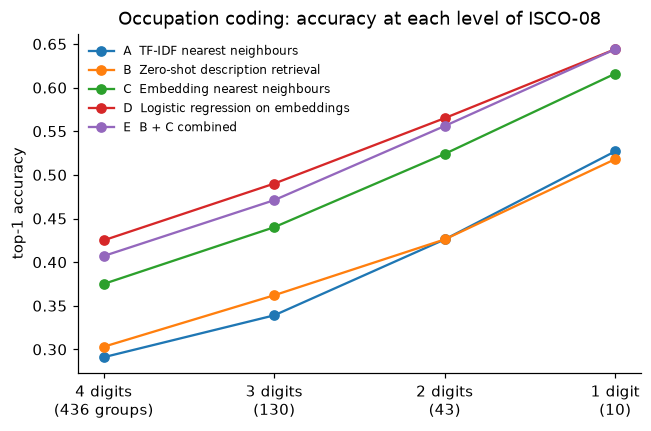

In [27]:
occ_results = results_table("4 ISCO")
display(occ_results)

fig, ax = plt.subplots(figsize=(6.6, 4))
levels = ["top1_4digit", "top1_3digit", "top1_2digit", "top1_1digit"]
for name, r in occ_results.iterrows():
    ax.plot([4, 3, 2, 1], r[levels].to_numpy(dtype=float), "o-", label=name)
ax.set_xticks([4, 3, 2, 1], ["4 digits\n(436 groups)", "3 digits\n(130)", "2 digits\n(43)", "1 digit\n(10)"])
ax.invert_xaxis()
ax.set_ylabel("top-1 accuracy")
ax.set_title("Occupation coding: accuracy at each level of ISCO-08")
ax.legend(frameon=False, fontsize=8)
plt.show()

### 4.6 Spanish job titles

The titles below were written for this class as typical of what appears in Peruvian job ads and survey responses. Nothing in training was in Spanish. We use method B (descriptions) and method C (neighbours) and show the top three ISCO groups for each title.

Judge the output yourself. Where the first suggestion is wrong, is the right group in the top three? Which titles depend on local knowledge that an international model is unlikely to have?

In [28]:
spanish_titles = [
    "analista de riesgo crediticio",
    "chofer de combi",
    "cajero de banco",
    "profesora de inicial",
    "técnico en enfermería",
    "vendedor ambulante de comida",
    "ingeniero de minas",
    "asistente contable",
]
E_es = embed(spanish_titles)
scores_es = unit_scale(E_es @ E_isco.T) + unit_scale(
    knn_class_scores(E_es, E_occ_train, y_occ_train, len(ISCO_CODES))
)
suggestions = []
for title, s in zip(spanish_titles, scores_es):
    best = np.argsort(-s)[:3]
    suggestions.append({"title": title, **{f"suggestion {i + 1}": f"{ISCO_CODES[j]} {isco_name[ISCO_CODES[j]]}"
                                           for i, j in enumerate(best)}})
display(pd.DataFrame(suggestions))

,title,suggestion 1,suggestion 2,suggestion 3
0,analista de riesgo crediticio,2413 Financial analysts,3312 Credit and loans officers,3311 Securities and finance dealers and brokers
1,chofer de combi,5111 Travel attendants and travel stewards,0210 Non-commissioned armed forces officers,3434 Chefs
2,cajero de banco,1346 Financial and insurance services branch managers,4211 Bank tellers and related clerks,"4212 Bookmakers, croupiers and related gaming workers"
3,profesora de inicial,2352 Special needs teachers,3253 Community health workers,2262 Pharmacists
4,técnico en enfermería,3114 Electronics engineering technicians,3141 Life science technicians (excluding medical),3240 Veterinary technicians and assistants
5,vendedor ambulante de comida,5223 Shop sales assistants,5212 Street food salespersons,5211 Stall and market salespersons
6,ingeniero de minas,2151 Electrical engineers,3121 Mining supervisors,7233 Agricultural and industrial machinery mechanics and repairers
7,asistente contable,2411 Accountants,3411 Legal and related associate professionals,"4312 Statistical, finance and insurance clerks"


### What to take from Module 4

* **With hundreds of classes, think of retrieval, not only classification.** A classifier can only choose among the classes it was trained on. Retrieval over class descriptions can reach classes with no examples at all.
* **Class descriptions are data.** Any official classification (ISCO, ISIC/CIIU for industries, HS for traded goods, COICOP for consumption) comes with written definitions. Embedding those gives you a working system before you label a single example.
* **Match the metric to the research question.** Decide which level of the hierarchy your analysis needs before judging a model. Report top-k when a human will review the output.
* **How you split the data decides what the number means.** A random split here would have looked much better and told you much less.

### Exercises

1. **The optimistic split.** Replace `GroupShuffleSplit` with a plain random split of titles. By how much does each method improve? Which number would you report in a paper, and why?
2. **Descriptions against names.** In 4.3, embed only `isco4["label"]` without the description. How much of method B's performance comes from the description text?
3. **Industries.** Download the CIIU Rev. 4 structure from INEI and build a zero-shot coder for free-text descriptions of business activity using method B.
4. **Where do errors land?** For method E, tabulate true major group against predicted major group. Are errors spread evenly, or concentrated between particular pairs? What would that do to an estimate of the wage gap between those groups?

---
# Module 5 — Domain shift: sentiment in informal Spanish

### The real problem

Social media is an attractive data source for economists: it is immediate, abundant and free. Researchers have used it to track consumer mood, reactions to policy announcements, and expectations ahead of official statistics.

The text looks nothing like what most language models were trained on. Compare these two sentences, both invented for illustration:

> *La actividad económica registró una expansión moderada durante el trimestre.*

> *jajaja ya fue, otra vez subió el dólar, toy misio hasta fin de mes 😭*

Both are Spanish. A model that learned Spanish from Wikipedia and newspapers has seen thousands of sentences like the first and almost none like the second: no accents, phonetic spelling, regional slang, emoji carrying the sentiment. When training text and real-world text differ like this, we call it **domain shift**. It is one of the most common reasons a model that looked good in a paper disappoints in a project.

### The data

Spanish tweets labelled negative, neutral or positive, from the multilingual benchmark of **Barbieri et al. (2022), XLM-T**. According to the benchmark's authors, the Spanish portion comes from the TASS shared task on Spanish sentiment analysis. It is balanced: one third of each class.

* `data/tweets_es/train.csv` — 1,839 tweets
* `data/tweets_es/val.csv` — 324 tweets
* `data/tweets_es/test.csv` — 870 tweets

These are real tweets on any topic, not specifically economic ones, and **some contain coarse language**. User names were replaced with `@user` by the dataset's authors.

### Two experiments

**Part A: off-the-shelf models.** Two ready-made sentiment classifiers downloaded and used as they are, with no training on our side. One learned sentiment from product reviews; the other from tweets. Same language, same task, different domain.

**Part B: same data, different pretraining.** We fine-tune two Spanish encoders on exactly the same 1,839 tweets. **BETO** was pretrained on formal Spanish (Wikipedia, news, official documents). **RoBERTuito** was pretrained on about 500 million tweets. The only difference between the two runs is what kind of Spanish each model read *before* we showed it any labels.

### Before you run

1. A model trained on product reviews sees a tweet with no opinion in it (*"alguien sabe a qué hora juega la selección?"*). Reviews are almost never neutral. What will it predict?
2. In Part B both models get identical labelled data. Do you expect a gap of 1 point, 5 points or 15 points in macro-F1?
3. On which kind of tweet do you expect the formal-Spanish model to lose the most?

In [29]:
SENT_LABELS = ["negative", "neutral", "positive"]

tw_train = pd.read_csv(DATA / "tweets_es" / "train.csv")
tw_val = pd.read_csv(DATA / "tweets_es" / "val.csv")
tw_test = pd.read_csv(DATA / "tweets_es" / "test.csv")
y_tw_train, y_tw_test = tw_train["label"].to_numpy(), tw_test["label"].to_numpy()

print(f"train {len(tw_train)}  validation {len(tw_val)}  test {len(tw_test)}")
print(tw_train["label_name"].value_counts().to_string())
display(tw_train.groupby("label_name").sample(2, random_state=7)[["text", "label_name"]])

train 1839  validation 324  test 870
label_name
negative    613
neutral     613
positive    613


,text,label_name
879,Mañana me sacan sangre y tengo que ir en ayunas. Dadme ánimos ante esta situación tan heavy que me está tocando vivir,negative
1503,@user Gracias por la información. Parece que el olor ha cesado. Ayer pasó lo mismo sobre la misma hora,negative
1102,"@user @user @user Más bien imposible. A no ser q se convierta al Islam, claro",neutral
358,¿Un poquito de DB película 4 en catalán? Nueva lista en nuestro canal de YouTube http,neutral
1754,@user ha aceptado reembolsarme la cobertura marítima de la que no me advirtió en su momento. Estoy contenta. Me parece justo.,positive
1232,@user have fun Antu! Los mejores deseos,positive


### 5.1 Baseline

The usual first step. Tweets are short and spelling is irregular, so we count character sequences as well as words.

In [30]:
from sklearn.pipeline import make_union

tw_tfidf = make_pipeline(
    make_union(
        TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=2),
        TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True, min_df=2),
    ),
    LogisticRegression(C=5, max_iter=3000),
)
tw_tfidf.fit(tw_train["text"], y_tw_train)
pred_tw_tfidf = tw_tfidf.predict(tw_test["text"])
score("5 Tweets", "TF-IDF + LR (trained on these tweets)", y_tw_test, pred_tw_tfidf);

TF-IDF + LR (trained on these tweets)      accuracy 0.548   macro-F1 0.547


### 5.2 Part A — off-the-shelf models

Using a published classifier takes three steps: load it, run it, and **translate its labels into yours**. The third step is where mistakes hide.

* The review model predicts **1 to 5 stars**. We map 1–2 stars to negative, 3 to neutral, 4–5 to positive, adding up the probabilities within each group.
* The tweet model predicts `NEG`, `NEU`, `POS`.

A caveat on the comparison: the tweet model was trained by its authors on a TASS corpus, and our test tweets also come from TASS. We have not checked whether any of our test tweets were in its training data. Treat its score as an optimistic reference, not a clean out-of-sample result. This kind of overlap between public models and public benchmarks is common, and it is a reason to build your own small test set for anything that matters.

In [31]:
def prepare_tweet(text: str) -> str:
    """Light normalisation in the style RoBERTuito was trained with."""
    text = text.replace("@user", "@usuario")
    return re.sub(r"https?://\S+", "url", text)


def run_ready_made(model_id: str, texts) -> tuple[np.ndarray, list[str]]:
    tok = AutoTokenizer.from_pretrained(model_id)
    model = AutoModelForSequenceClassification.from_pretrained(model_id)
    proba = softmax(predict_logits(tok, model, texts, max_len=96))
    names = [model.config.id2label[i] for i in range(proba.shape[1])]
    free_memory(model)
    return proba, names


# Review model: stars -> three classes
proba_stars, star_names = run_ready_made(MODELS["sent_reviews"], tw_test["text"])
print("review model labels:", star_names)
stars = np.array([int(re.search(r"\d", n).group()) for n in star_names])
proba_reviews = np.column_stack(
    [proba_stars[:, stars <= 2].sum(1), proba_stars[:, stars == 3].sum(1), proba_stars[:, stars >= 4].sum(1)]
)
pred_tw_reviews = proba_reviews.argmax(axis=1)
score("5 Tweets", "Review model, off the shelf", y_tw_test, pred_tw_reviews)

# Tweet model: NEG / NEU / POS -> our order
proba_tw, tw_names = run_ready_made(MODELS["sent_tweets"], tw_test["text"].map(prepare_tweet))
print("tweet model labels:", tw_names)
order = [tw_names.index(n) for n in ("NEG", "NEU", "POS")]
pred_tw_ready = proba_tw[:, order].argmax(axis=1)
score("5 Tweets", "Tweet model, off the shelf", y_tw_test, pred_tw_ready);

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

review model labels: ['1 star', '2 stars', '3 stars', '4 stars', '5 stars']
Review model, off the shelf                accuracy 0.498   macro-F1 0.410


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tweet model labels: ['NEG', 'NEU', 'POS']
Tweet model, off the shelf                 accuracy 0.769   macro-F1 0.766


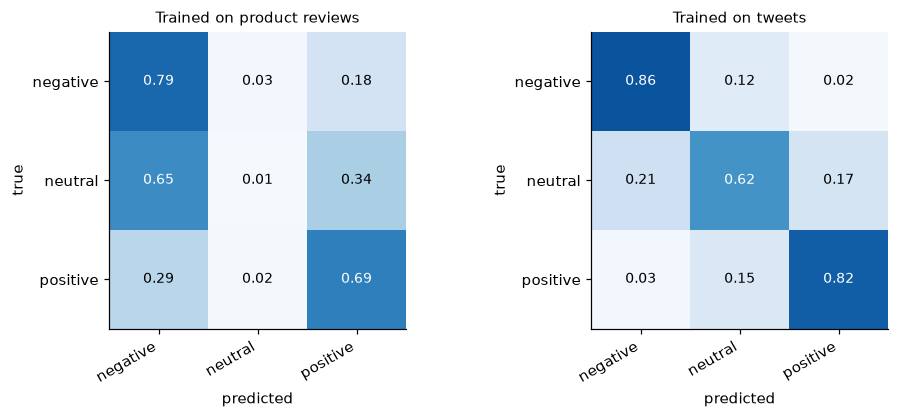

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.9))
plot_confusion(y_tw_test, pred_tw_reviews, SENT_LABELS, "Trained on product reviews", axes[0])
plot_confusion(y_tw_test, pred_tw_ready, SENT_LABELS, "Trained on tweets", axes[1])
plt.tight_layout()
plt.show()

Look at the **neutral row** of the left-hand matrix. Was your answer to question 1 right? A classifier can only reproduce the distribution of labels it was trained on. Product reviews are written by people with an opinion, so the model has little experience of text with none.

For an economist this is a measurement problem with a direction: an index built from the review model would misread plain statements as sentiment, and the error would not average out.

### 5.3 Part B — same labels, different pretraining

Now a controlled comparison. Both models are fine-tuned with the same function, on the same tweets, for the same number of epochs.

In [33]:
if FAST_MODE:
    tw_fit = tw_train.groupby("label", group_keys=False).sample(n=200, random_state=SEED)
    TW_EPOCHS = 2
else:
    tw_fit = tw_train
    TW_EPOCHS = 4

pred_tw = {}
for key, name, prep in [
    ("beto", "BETO (formal Spanish), fine-tuned", lambda t: t),
    ("robertuito", "RoBERTuito (tweets), fine-tuned", prepare_tweet),
]:
    print(f"Fine-tuning {MODELS[key]} on {len(tw_fit)} tweets")
    tok, model = finetune(
        MODELS[key],
        tw_fit["text"].map(prep).tolist(),
        tw_fit["label"].to_numpy(),
        SENT_LABELS,
        epochs=TW_EPOCHS,
        lr=3e-5,
        batch_size=32,
        max_len=96,
    )
    pred_tw[key] = predict_logits(tok, model, tw_test["text"].map(prep), max_len=96).argmax(axis=1)
    score("5 Tweets", name, y_tw_test, pred_tw[key])
    free_memory(model)
    del model

display(results_table("5 Tweets"))

Fine-tuning dccuchile/bert-base-spanish-wwm-cased on 600 tweets


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: dccuchile/bert-base-spanish-wwm-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 
classifier.weight                          | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	

  epoch 1/2  mean loss 1.0586  (75s elapsed)


  epoch 2/2  mean loss 0.8199  (147s elapsed)


...

[transformers] RobertaForSequenceClassification LOAD REPORT from: pysentimiento/robertuito-base-uncased
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  epoch 1/2  mean loss 1.0810  (66s elapsed)


  epoch 2/2  mean loss 0.9311  (130s elapsed)


RoBERTuito (tweets), fine-tuned            accuracy 0.571   macro-F1 0.559


,accuracy,macro_f1
model,,
TF-IDF + LR (trained on these tweets),0.548,0.547
"Review model, off the shelf",0.498,0.410
"Tweet model, off the shelf",0.769,0.766
"BETO (formal Spanish), fine-tuned",0.585,0.553
"RoBERTuito (tweets), fine-tuned",0.571,0.559


### 5.4 Where does the formal model lose?

An average hides where the damage is. We split the test tweets by a crude marker of informality: laughter (*jaja*), letters repeated three or more times (*buenooo*), repeated punctuation, or emoticons. Then we compare accuracy within each group.

If domain shift is the explanation, the gap between the two models should be wider on the informal tweets. If the gap is the same in both groups, something else is going on, and the regular expression is probably a poor measure of informality. Either result teaches you something about the data.

In [34]:
INFORMAL = re.compile(r"(?i)(ja|je|ji){2,}|(\w)\2{2,}|[!?]{2,}|\bxd\b|:v|:\)|:\(|<3")
tw_test["informal"] = tw_test["text"].map(lambda t: bool(INFORMAL.search(t)))

slices = []
for key, name in [("beto", "BETO"), ("robertuito", "RoBERTuito")]:
    for flag, label in [(False, "plain"), (True, "informal markers")]:
        mask = (tw_test["informal"] == flag).to_numpy()
        slices.append({"model": name, "tweets": label, "n": int(mask.sum()),
                       "accuracy": accuracy_score(y_tw_test[mask], pred_tw[key][mask])})
display(pd.DataFrame(slices).pivot(index="tweets", columns="model", values="accuracy").round(3))
print(tw_test["informal"].value_counts().rename({True: "informal markers", False: "plain"}).to_string())

both_wrong = tw_test[(pred_tw["beto"] != y_tw_test) & (pred_tw["robertuito"] == y_tw_test)]
print(f"\nTweets RoBERTuito gets right and BETO gets wrong: {len(both_wrong)}. A few of them:")
display(both_wrong[["text", "label_name"]].head(8))

model,BETO,RoBERTuito
tweets,,
informal markers,0.582,0.627
plain,0.586,0.563


informal
plain               760
informal markers    110

Tweets RoBERTuito gets right and BETO gets wrong: 121. A few of them:


,text,label_name
7,Parce yo estoy igual @user,neutral
8,@user pues no está nada mal,positive
25,"@user Asegúrate de que no es cuestión de tu dispositivo o conexión a internet. Si es es así, envíanos un mail a info@wuolah.com",neutral
28,@user por eso yo también tengo mis bias.. y apoyo a los demás pero la mayoría del fandom no y pos..,neutral
42,"Todo el mundo con la segunda temporada de Narcos y yo no, PORQUE NO TENGO NETFLIX @user pasaros una suscripcion de 5 dias",negative
43,Me gusta estar sola y me molesta la gente que habla mucho. Si tan solo nos juntáramos a escuchar música y de rato en rato hablar de ello,neutral
45,súper luna llena significa que la gente va a andar loca por dos semanas a partir de hoy en la mañana. Let the Hunger Games begin!,negative
57,Que huevada es trabajar feriado,negative


### What to take from Module 5

* **"Spanish" is not one domain.** A model's training text matters as much as its language. Before choosing a model, read its card and ask: what did it read, and does my text look like that?
* **Off-the-shelf models carry their training labels with them.** A model trained on a source with no neutral texts will rarely answer "neutral". Check the label distribution of its predictions against what you expect.
* **Evaluate on your own text.** Published scores describe the benchmark, not your data. A hundred examples labelled by you are worth more than any leaderboard.
* **Slice the errors.** An overall metric tells you that a model fails; a breakdown by type of text tells you where, and whether the failures are correlated with something you care about.

**A warning for economists.** Even a perfect classifier does not make Twitter a random sample. People who post are younger, more urban and more politically engaged than the population, and who posts changes over time. A sentiment index from social media measures the mood of people who post. Whether that is the quantity your research question needs is a sampling question, and no model can answer it.

### Exercises

1. **Peruvian Spanish.** Collect 60 short public comments in Peruvian Spanish about prices or the exchange rate and label them yourselves. Evaluate both fine-tuned models. Is the ranking the same as on the benchmark?
2. **Preprocessing.** Fine-tune RoBERTuito without `prepare_tweet`. Does it matter? Then try the full `preprocess_tweet` function from the `pysentimiento` library.
3. **Seeds again.** Repeat Part B with three seeds. Is the gap between the two models larger than the spread across seeds?
4. **The other direction.** Apply the tweet model from Part A to the Spanish central-bank sentences of Module 1. What does it call a sentence about raising interest rates? Is "negative" the same thing as "hawkish"?

---
# Module 6 — From classifier to regression

A classifier in a research project is rarely the end product. Its output becomes an input: a threshold that triggers a decision, or a variable in a regression. This module covers what that step requires. None of it is specific to one model; all of it applies to everything above.

1. **Calibration.** When the model says 90%, is it right 90% of the time?
2. **Decisions.** Which predictions do you act on automatically, and which do you send to a person?
3. **Aggregation.** Turning 20,000 classified sentences into a time series of central bank tone.
4. **Measurement error.** What classification mistakes do to a regression coefficient, and how to correct for them.

## 6.1 Calibration

A model's output probabilities are only useful as probabilities if they are **calibrated**: among all predictions made with confidence 0.8, about 80% should be correct. Fine-tuned neural networks are typically *over-confident*; they say 0.99 when they are right 85% of the time.

**How to see it.** A reliability diagram groups predictions by confidence and plots the accuracy within each group. A calibrated model lies on the diagonal. The **expected calibration error (ECE)** summarises the diagram in one number: the average distance from the diagonal, weighted by how many predictions fall in each group.

**How to fix it.** *Temperature scaling* (Guo et al., 2017) divides all the logits by a single number `T` before the softmax. `T > 1` softens the probabilities. We choose `T` to maximise the likelihood of the **validation** labels. Because dividing every score by the same number does not change which one is largest, predictions and accuracy stay exactly the same; only the confidence changes.

**Before you run:** will the fitted `T` be above or below 1? What would `T < 1` mean?

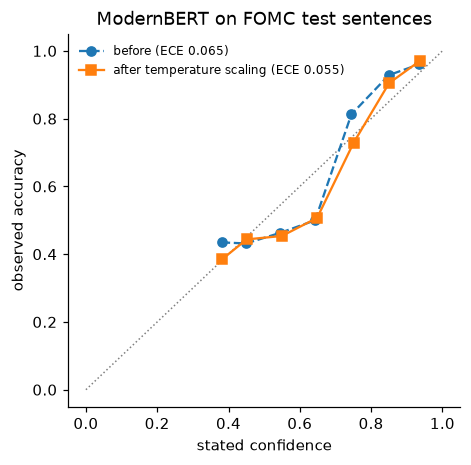

fitted temperature T = 0.92
test log-loss before 0.910   after 0.912
mean confidence before 0.583   after 0.598   accuracy 0.559


In [35]:
from scipy.optimize import minimize_scalar


def nll(logits: np.ndarray, y: np.ndarray, T: float = 1.0) -> float:
    """Average negative log-likelihood of the true labels."""
    p = softmax(logits / T)
    return float(-np.log(p[np.arange(len(y)), y] + 1e-12).mean())


def reliability(proba: np.ndarray, y: np.ndarray, bins: int = 10):
    """Per-bin confidence, accuracy and share of predictions, plus the ECE."""
    conf, pred = proba.max(axis=1), proba.argmax(axis=1)
    edges = np.linspace(0, 1, bins + 1)
    which = np.clip(np.digitize(conf, edges[1:-1]), 0, bins - 1)
    table = []
    for b in range(bins):
        m = which == b
        if m.any():
            table.append((conf[m].mean(), (pred[m] == y[m]).mean(), m.mean()))
    table = np.array(table)
    ece = float(np.sum(table[:, 2] * np.abs(table[:, 0] - table[:, 1])))
    return table, ece


T_FOMC = minimize_scalar(lambda T: nll(logits_fomc_val, y_fomc_val, T), bounds=(0.05, 20), method="bounded").x
proba_raw = softmax(logits_fomc_test)
proba_cal = softmax(logits_fomc_test / T_FOMC)

fig, ax = plt.subplots(figsize=(4.6, 4.4))
ax.plot([0, 1], [0, 1], color="grey", lw=1, ls=":")
for proba, label, style in [(proba_raw, "before", "o--"), (proba_cal, "after temperature scaling", "s-")]:
    table, ece = reliability(proba, y_fomc_test)
    ax.plot(table[:, 0], table[:, 1], style, label=f"{label} (ECE {ece:.3f})")
ax.set_xlabel("stated confidence")
ax.set_ylabel("observed accuracy")
ax.set_title("ModernBERT on FOMC test sentences")
ax.legend(frameon=False, fontsize=8)
plt.show()

print(f"fitted temperature T = {T_FOMC:.2f}")
print(f"test log-loss before {nll(logits_fomc_test, y_fomc_test):.3f}   after {nll(logits_fomc_test, y_fomc_test, T_FOMC):.3f}")
print(f"mean confidence before {proba_raw.max(1).mean():.3f}   after {proba_cal.max(1).mean():.3f}"
      f"   accuracy {accuracy_score(y_fomc_test, proba_raw.argmax(1)):.3f}")

With only a few hundred test sentences, the bins of a reliability diagram are noisy; do not over-read a single point. The log-loss and the comparison of mean confidence with accuracy are the steadier summaries.

## 6.2 Decisions: when should a person look?

Return to the message-routing problem of Module 3. In production the system does not have to decide every case. It can **route automatically** when it is confident and **send the rest to a person**. That gives one number to choose, a confidence threshold τ, and a trade-off:

* **Coverage**: the share of messages handled automatically.
* **Selective accuracy**: the accuracy on those messages.

Raising τ lowers coverage and raises selective accuracy. The right τ is not a statistical question. It depends on costs: what a wrongly routed message costs (delay, an unhappy customer, a regulatory deadline missed) compared with what a manual review costs.

**Doing it honestly.** If you choose τ on the same data you report results on, the result is optimistic. We split the test set in two: choose τ on one half, report on the other.

**Before you run:** if a wrong routing costs 10 times a manual review, roughly what share of messages do you expect to send to a person?

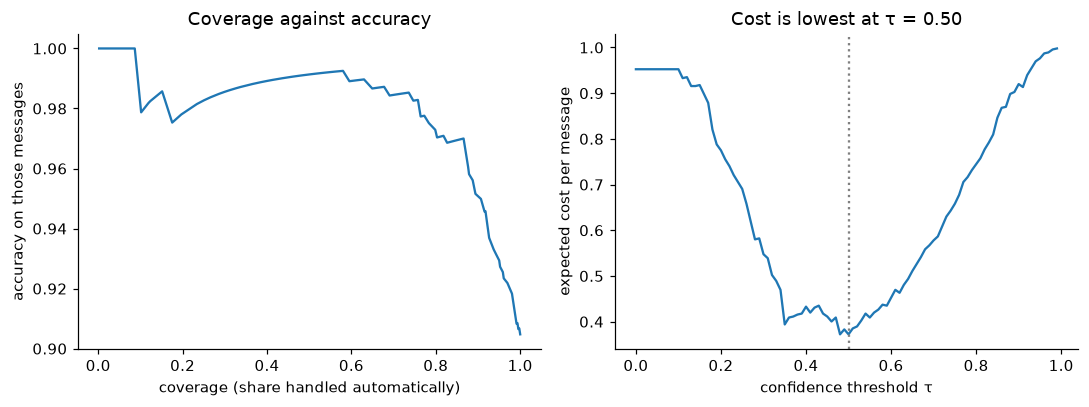

Evaluated on the half of the test set that was NOT used to choose τ:


,threshold,coverage,selective_accuracy,cost_per_message
policy,,,,
route everything automatically,0.00,1.000,0.848,1.515
review when confidence < 0.50,0.50,0.682,0.962,0.578
review everything,1.01,0.000,NaN,1.000


In [36]:
COST_ERROR = 10.0   # cost of routing a message to the wrong team
COST_REVIEW = 1.0   # cost of having a person route it

conf_b77, pred_b77 = proba_b77_test.max(axis=1), head_full.classes_[proba_b77_test.argmax(axis=1)]
correct_b77 = pred_b77 == y_b77_test
rng = np.random.default_rng(SEED)
pick = rng.permutation(len(y_b77_test))
choose, report = pick[: len(pick) // 2], pick[len(pick) // 2 :]


def operating_point(idx: np.ndarray, tau: float) -> dict:
    auto = conf_b77[idx] >= tau
    errors = (~correct_b77[idx] & auto).mean()   # share of all messages routed wrongly
    reviewed = (~auto).mean()                    # share of all messages sent to a person
    return {
        "threshold": tau,
        "coverage": auto.mean(),
        "selective_accuracy": correct_b77[idx][auto].mean() if auto.any() else np.nan,
        "cost_per_message": COST_ERROR * errors + COST_REVIEW * reviewed,
    }


grid = np.linspace(0, 0.99, 100)
curve_choose = pd.DataFrame([operating_point(choose, t) for t in grid])
best_tau = curve_choose.loc[curve_choose["cost_per_message"].idxmin(), "threshold"]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].plot(curve_choose["coverage"], curve_choose["selective_accuracy"])
axes[0].set_xlabel("coverage (share handled automatically)")
axes[0].set_ylabel("accuracy on those messages")
axes[0].set_title("Coverage against accuracy")
axes[1].plot(curve_choose["threshold"], curve_choose["cost_per_message"])
axes[1].axvline(best_tau, color="grey", ls=":")
axes[1].set_xlabel("confidence threshold τ")
axes[1].set_ylabel("expected cost per message")
axes[1].set_title(f"Cost is lowest at τ = {best_tau:.2f}")
plt.tight_layout()
plt.show()

summary = pd.DataFrame(
    [
        {"policy": "route everything automatically", **operating_point(report, 0.0)},
        {"policy": f"review when confidence < {best_tau:.2f}", **operating_point(report, best_tau)},
        {"policy": "review everything", **operating_point(report, 1.01)},
    ]
).set_index("policy")
print("Evaluated on the half of the test set that was NOT used to choose τ:")
display(summary.round(3))

Change `COST_ERROR` to 2 and to 50 and rerun the cell. The model has not changed; the best policy has. A threshold only means something when the probabilities are calibrated (6.1) and the costs are stated.

## 6.3 From sentences to a time series

This is the payoff of Module 1. We take **every** sentence in the FOMC meeting minutes from 1996 to 2022 (about 20,000 sentences across 214 meetings, almost none of which were labelled by hand), classify each with our fine-tuned model, and summarise each meeting as

$$\text{tone}_t = \frac{\#\text{hawkish}_t - \#\text{dovish}_t}{\#\text{sentences}_t}$$

which runs from −1 (every sentence dovish) to +1 (every sentence hawkish).

Two checks before trusting it:

* **Against the original authors.** The file includes the labels produced by the authors' own, much larger model, and their published index. If our index tracks theirs, a second model has reached a similar reading of the text.
* **Against the economy.** A stance index that bore no relation to inflation or interest rates would be suspect.

Scoring 20,000 sentences takes about a minute on a GPU and several on a CPU. In `FAST_MODE` we score every fourth meeting.

In [37]:
minutes = pd.read_csv(DATA / "fomc" / "minutes_sentences.csv", dtype={"meeting_id": str})
meetings = pd.read_csv(DATA / "fomc" / "meetings.csv", dtype={"meeting_id": str},
                       parse_dates=["meeting_date", "release_date"])
if FAST_MODE:
    meetings = meetings.iloc[::4].reset_index(drop=True)
    minutes = minutes[minutes["meeting_id"].isin(meetings["meeting_id"])].reset_index(drop=True)
print(f"scoring {len(minutes)} sentences from {len(meetings)} meetings")

proba_minutes = softmax(predict_logits(fomc_tok, fomc_model, minutes["sentence"].astype(str)) / T_FOMC)
minutes["our_label"] = proba_minutes.argmax(axis=1)


def tone_index(labels: pd.Series) -> float:
    return ((labels == 1).sum() - (labels == 0).sum()) / len(labels)


by_meeting = minutes.groupby("meeting_id").agg(
    tone_ours=("our_label", tone_index),
    tone_authors_labels=("authors_label", tone_index),
    sentences=("sentence", "size"),
)
tone = meetings.merge(by_meeting, on="meeting_id").sort_values("meeting_date").reset_index(drop=True)

agreement = (minutes["our_label"] == minutes["authors_label"]).mean()
print(f"sentence-level agreement between our model and the authors' model: {agreement:.1%}")
print(f"correlation of the two meeting-level indices: {tone['tone_ours'].corr(tone['tone_authors_labels']):.3f}")

scoring 5245 sentences from 54 meetings


sentence-level agreement between our model and the authors' model: 40.1%
correlation of the two meeting-level indices: 0.726


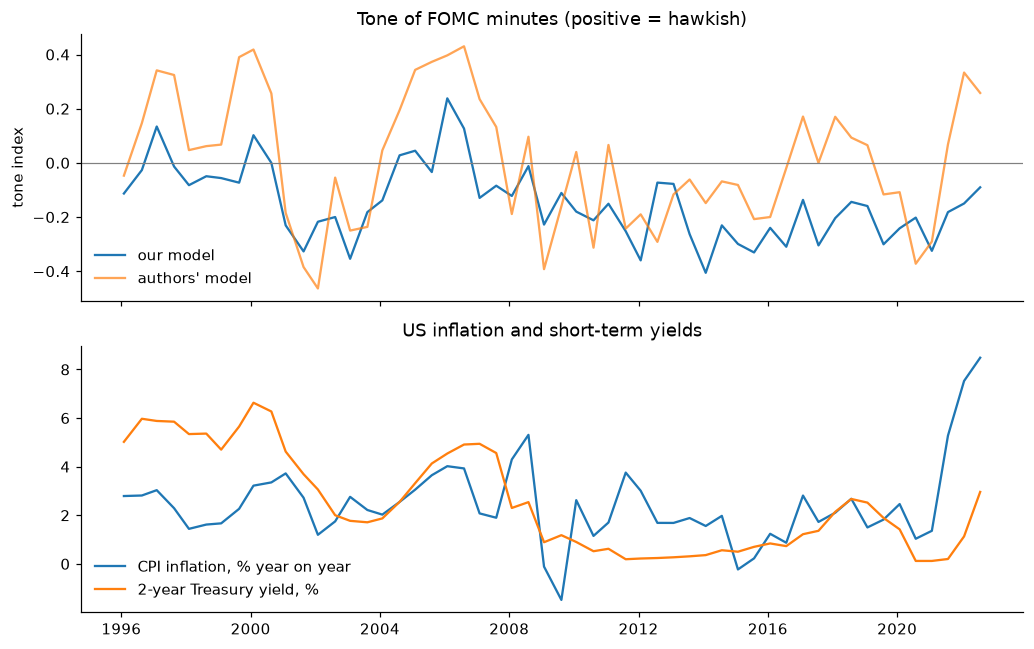

In [38]:
# Economic series: CPI inflation (year on year) and the 2-year Treasury yield.
cpi = pd.read_csv(DATA / "fomc" / "cpi.csv", parse_dates=["date"]).sort_values("date")
cpi["inflation"] = 100 * (cpi["cpi"] / cpi["cpi"].shift(12) - 1)
yields = pd.read_csv(DATA / "fomc" / "treasury_yields.csv", parse_dates=["date"]).dropna(subset=["y2"]).sort_values("date")

tone["month"] = tone["meeting_date"].dt.to_period("M").dt.to_timestamp()
tone = tone.merge(cpi[["date", "inflation"]].rename(columns={"date": "month"}), on="month", how="left")
tone = pd.merge_asof(tone, yields[["date", "y2"]], left_on="meeting_date", right_on="date", direction="backward")

fig, axes = plt.subplots(2, 1, figsize=(9.5, 6), sharex=True)
axes[0].plot(tone["meeting_date"], tone["tone_ours"], label="our model")
axes[0].plot(tone["meeting_date"], tone["tone_authors_labels"], label="authors' model", alpha=0.7)
axes[0].axhline(0, color="grey", lw=0.8)
axes[0].set_ylabel("tone index")
axes[0].set_title("Tone of FOMC minutes (positive = hawkish)")
axes[0].legend(frameon=False)
axes[1].plot(tone["meeting_date"], tone["inflation"], label="CPI inflation, % year on year")
axes[1].plot(tone["meeting_date"], tone["y2"], label="2-year Treasury yield, %")
axes[1].set_title("US inflation and short-term yields")
axes[1].legend(frameon=False)
plt.tight_layout()
plt.show()

Now a regression, of the kind you would actually run: is the Committee's language more hawkish when inflation is higher? We regress the tone index on inflation in the month of the meeting. Meetings are eight per year and tone is persistent, so the errors are serially correlated; we use Newey–West (HAC) standard errors.

**Read this as a description, not a causal estimate.** Inflation, tone and the policy rate are jointly determined, and the specification is deliberately minimal. The point here is the mechanics: a classifier's output has become the dependent variable of a regression.

In [39]:
import statsmodels.formula.api as smf

reg_data = tone.dropna(subset=["tone_ours", "inflation", "y2"]).copy()
reg_data["d_y2_next"] = reg_data["y2"].shift(-1) - reg_data["y2"]  # change in the 2-year yield up to the next meeting

fit_level = smf.ols("tone_ours ~ inflation", data=reg_data).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
fit_ahead = smf.ols("d_y2_next ~ tone_ours", data=reg_data.dropna(subset=["d_y2_next"])).fit(
    cov_type="HAC", cov_kwds={"maxlags": 4}
)
print("(1) tone on inflation")
print(fit_level.summary().tables[1])
print("\n(2) change in the 2-year yield up to the next meeting, on tone")
print(fit_ahead.summary().tables[1])

(1) tone on inflation
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.2120      0.036     -5.845      0.000      -0.283      -0.141
inflation      0.0266      0.014      1.952      0.051      -0.000       0.053

(2) change in the 2-year yield up to the next meeting, on tone
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.0521      0.180     -0.290      0.772      -0.404       0.300
tone_ours     -0.0894      0.660     -0.135      0.892      -1.383       1.204


## 6.4 Measurement error: the classifier is not the truth

Regression (2) above puts a **predicted** variable on the right-hand side. Our model disagrees with the human labels on a substantial share of test sentences. The tone index is therefore measured with error, and from econometrics you know what that can do to a coefficient.

There are two forces, and they pull in opposite directions.

* **Random noise in the index** (some meetings scored too high, some too low, unrelated to the truth) biases the coefficient **toward zero**. This is classical attenuation.
* **Systematic compression.** A classifier that mislabels some hawkish and dovish sentences as neutral, or confuses the two with each other, produces an index that moves *less* than the truth: when the true tone rises by 1, the measured tone rises by less than 1. A regressor that is a shrunken copy of the true one produces a coefficient that is **too large**.

Which force wins depends on the classifier's confusion matrix and on how many sentences each document has. You cannot sign the bias by reasoning alone. So we measure it, in a setting where we know the truth.

### A simulation built from the real classifier

1. Build 400 artificial "meetings". Each is 60 sentences drawn from the **hand-labelled test set**, with a different mix of hawkish, dovish and neutral in each.
2. For every artificial meeting compute the **true** tone (from the human labels) and the **measured** tone (from our model's predictions on those same sentences). The classification errors are real; only the grouping into meetings is artificial.
3. Simulate an outcome with a known effect: `y = 1.0 × true tone + noise`. The right answer is **1.0**.
4. Estimate the coefficient four ways:
   * **Oracle**: regress `y` on the true tone. Not available in practice; it is the reference.
   * **Naive**: regress `y` on the measured tone, as in regression (2).
   * **Labelled subsample only**: hand-label 60 of the 400 meetings and use only those. Unbiased, but it throws away 85% of the data.
   * **Corrected**: on the 60 labelled meetings, estimate how true tone relates to measured tone. Use that relationship to predict the true tone for all 400, and regress `y` on the prediction. This is *regression calibration*. It is valid when the classifier's errors are unrelated to the outcome once true tone is accounted for.

We repeat the whole exercise 300 times to see the distribution of each estimator, not one lucky draw.

**Before you run:** will the naive coefficient be above or below 1?

true coefficient = 1.0


,mean estimate,bias,std. dev. across replications,root mean squared error
oracle (true tone),1.001,0.001,0.046,0.046
naive (measured tone),1.332,0.332,0.194,0.385
labelled subsample only,0.999,-0.001,0.119,0.119
corrected (regression calibration),1.048,0.048,0.365,0.367


On average, a one-unit rise in measured tone corresponds to a 1.37-unit rise in true tone.


C:\Users\Jean Pool\AppData\Local\Temp\ipykernel_15368\1078954157.py:56: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot([estimators[c] for c in estimators.columns], vert=False, showfliers=False)


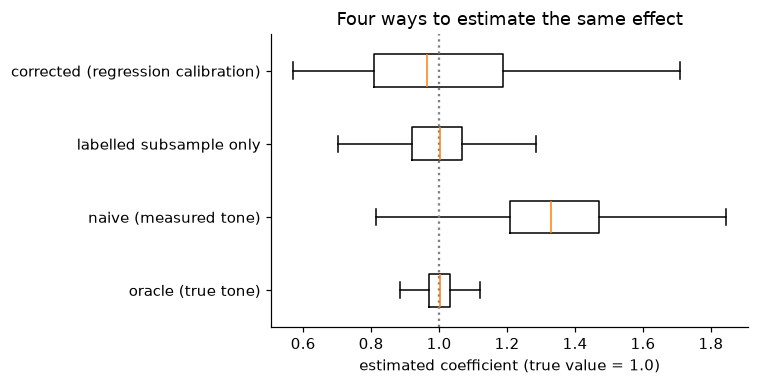

In [40]:
import statsmodels.api as sm

TRUE_BETA, N_DOCS, DOC_LEN, N_LABELLED, N_REPS = 1.0, 400, 60, 60, 300

gold, predicted = y_fomc_test, pred_fomc_bert
pools = [np.flatnonzero(gold == c) for c in range(3)]


def tone_of(labels: np.ndarray) -> np.ndarray:
    return ((labels == 1).sum(axis=1) - (labels == 0).sum(axis=1)) / labels.shape[1]


def slope(y: np.ndarray, x: np.ndarray) -> float:
    return float(sm.OLS(y, sm.add_constant(x, has_constant="add")).fit().params[1])


def one_replication(rng: np.random.Generator) -> dict:
    mix = rng.dirichlet([2.0, 2.0, 4.0], size=N_DOCS)                 # share of each class per meeting
    classes = np.stack([rng.choice(3, size=DOC_LEN, p=p) for p in mix])
    picks = np.empty_like(classes)
    for c in range(3):                                                # a real test sentence of each class
        where = classes == c
        picks[where] = rng.choice(pools[c], size=int(where.sum()))
    x_true, x_hat = tone_of(gold[picks]), tone_of(predicted[picks])
    y = TRUE_BETA * x_true + rng.normal(0, 0.25, N_DOCS)

    lab = rng.choice(N_DOCS, size=N_LABELLED, replace=False)          # meetings we "hand-label"
    calib = sm.OLS(x_true[lab], sm.add_constant(x_hat[lab], has_constant="add")).fit()
    x_corrected = calib.predict(sm.add_constant(x_hat, has_constant="add"))
    return {
        "oracle (true tone)": slope(y, x_true),
        "naive (measured tone)": slope(y, x_hat),
        "labelled subsample only": slope(y[lab], x_true[lab]),
        "corrected (regression calibration)": slope(y, x_corrected),
        "_compression": calib.params[1],
    }


rng = np.random.default_rng(SEED)
sims = pd.DataFrame([one_replication(rng) for _ in range(N_REPS)])
estimators = sims.drop(columns="_compression")
report_me = pd.DataFrame(
    {
        "mean estimate": estimators.mean(),
        "bias": estimators.mean() - TRUE_BETA,
        "std. dev. across replications": estimators.std(),
        "root mean squared error": np.sqrt(((estimators - TRUE_BETA) ** 2).mean()),
    }
)
print(f"true coefficient = {TRUE_BETA}")
display(report_me.round(3))
print(f"On average, a one-unit rise in measured tone corresponds to a "
      f"{sims['_compression'].mean():.2f}-unit rise in true tone.")

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.boxplot([estimators[c] for c in estimators.columns], vert=False, showfliers=False)
ax.set_yticks(range(1, len(estimators.columns) + 1), estimators.columns)
ax.axvline(TRUE_BETA, color="grey", ls=":")
ax.set_xlabel("estimated coefficient (true value = 1.0)")
ax.set_title("Four ways to estimate the same effect")
plt.tight_layout()
plt.show()

### Reading the simulation

* **Bias of the naive estimate.** Is it above or below 1, and by how much? Relate it to the last printed line: if a one-unit rise in measured tone corresponds to more than one unit of true tone, the measured index is compressed and the naive coefficient is inflated.
* **Labelled subsample only.** It should be centred on 1 with a wide spread. Unbiased and imprecise.
* **Corrected.** It should be centred near 1: the hand labels remove the bias. Now compare its spread, and its root mean squared error, with the labelled-only estimator. How much the model's predictions add depends on how good the classifier is. With an accurate classifier, the predictions on the 340 unlabelled meetings recover much of the lost precision. With a weak one, the corrected estimate may be no more precise than the hand labels alone, because the correction factor is itself estimated from only 60 meetings. Predictions add information in proportion to their quality.

One caution. The standard errors that OLS prints for the corrected regression are too small, because they ignore that the correction itself was estimated from 60 documents. In applied work, bootstrap the whole two-step procedure, or use an estimator designed for this setting: *prediction-powered inference* (Angelopoulos et al., 2023) or *design-based supervised learning* (Egami et al., 2023). Both formalise the same idea: a small set of human labels, chosen at random, is used to correct estimates built from a large set of model predictions.

**The practical rule: always hand-label a random sample of the documents you analyse, however good the classifier looks.** That sample is what allows you to quantify and correct the error in everything else.

---
# Closing: a checklist for your own project

**Before training anything**

1. What is the unit of text (sentence, document, message), and what is the label? Write the labelling instructions down. If two people cannot agree on the label, a model will not either.
2. How many labels can you afford? That decides the family of model: none (zero-shot retrieval, Module 4), a few per class (embeddings or SetFit, Module 3), hundreds or more per class (fine-tuning, Modules 1 and 5).
3. What language and register is the text in? Choose a model that has read similar text (Modules 1 and 5).

**While building**

4. Fit a TF-IDF baseline first.
5. Split the data the way the model will be used: by time, by source or by entity when new ones will appear (Module 4).
6. Report macro-F1 alongside accuracy, read the confusion matrix, and read the errors.

**Before using the output**

7. Check calibration if you use the probabilities (6.1).
8. State the costs if you set a threshold (6.2).
9. If predictions enter a regression, hand-label a random sample and correct for measurement error (6.4).
10. Ask who produced the text and who did not. A classifier cannot fix a sampling problem (Module 5).

### All results in one place

In [41]:
for module in sorted({r["module"] for r in RESULTS}):
    print(f"\nModule {module}")
    display(results_table(module))


Module 1 FOMC


,accuracy,macro_f1
model,,
Always 'neutral',0.473,0.214
TF-IDF + logistic regression,0.601,0.580
ModernBERT-base (fine-tuned),0.559,0.498
mmBERT-small (fine-tuned),0.511,0.417



Module 3 Banking77


,accuracy,macro_f1
model,,
"TF-IDF + LR, 8 per class",0.656,0.651
"Frozen E5 + LR, 8 per class",0.802,0.798
"SetFit, 8 per class",0.737,0.725
"TF-IDF + LR, all labels",0.838,0.834
"Frozen E5 + LR, all labels",0.877,0.875



Module 4 ISCO


,top1_4digit,top5_4digit,top1_3digit,top1_2digit,top1_1digit,top1_seen,top1_unseen
model,,,,,,,
A TF-IDF nearest neighbours,0.291,0.495,0.339,0.426,0.527,0.300,0.000
B Zero-shot description retrieval,0.303,0.557,0.362,0.426,0.518,0.295,0.542
C Embedding nearest neighbours,0.375,0.612,0.440,0.524,0.616,0.388,0.000
D Logistic regression on embeddings,0.425,0.665,0.490,0.565,0.644,0.439,0.000
E B + C combined,0.407,0.693,0.471,0.556,0.644,0.421,0.000



Module 5 Tweets


,accuracy,macro_f1
model,,
TF-IDF + LR (trained on these tweets),0.548,0.547
"Review model, off the shelf",0.498,0.410
"Tweet model, off the shelf",0.769,0.766
"BETO (formal Spanish), fine-tuned",0.585,0.553
"RoBERTuito (tweets), fine-tuned",0.571,0.559


### A project for the course

Build a monetary policy tone index for Peru.

1. Collect the BCRP's monthly *Notas Informativas del Programa Monetario* (public on the BCRP website) and split them into sentences.
2. Write labelling instructions. Have two people label a random sample of 300 sentences independently. Measure their agreement and resolve the disagreements.
3. Evaluate three options on your labels: the English-trained mmBERT from Module 1 applied directly; a frozen-embedding classifier trained on part of your labels (Module 3); a Spanish encoder fine-tuned on part of your labels (Module 5).
4. Score every sentence with the best one, build the index, and plot it against the BCRP reference rate and inflation expectations.
5. Use your hand labels to correct for measurement error, as in 6.4, in a regression of your choice.

### References

* Angelopoulos, Bates, Fannjiang, Jordan and Zrnic (2023). Prediction-powered inference. *Science*.
* Barbieri, Espinosa Anke and Camacho-Collados (2022). XLM-T: Multilingual language models in Twitter for sentiment analysis and beyond. *LREC*.
* Cañete, Chaperon, Fuentes, Ho, Kang and Pérez (2020). Spanish pre-trained BERT model and evaluation data (BETO). *PML4DC at ICLR*.
* Casanueva, Temčinas, Gerz, Henderson and Vulić (2020). Efficient intent detection with dual sentence encoders (Banking77). *NLP for Conversational AI workshop, ACL*.
* Egami, Hinck, Stewart and Wei (2023). Using imperfect surrogates for downstream inference: design-based supervised learning for social science applications of large language models. *NeurIPS*.
* Gentzkow, Kelly and Taddy (2019). Text as data. *Journal of Economic Literature*.
* Guo, Pleiss, Sun and Weinberger (2017). On calibration of modern neural networks. *ICML*.
* Marone, Weller, Fleshman, Yang, Lawrie and Van Durme (2025). mmBERT: a modern multilingual encoder with annealed language learning. *arXiv*.
* Pérez, Furman, Alonso Alemany and Luque (2022). RoBERTuito: a pre-trained language model for social media text in Spanish. *LREC*.
* Shah, Paturi and Chava (2023). Trillion dollar words: a new financial dataset, task and market analysis. *ACL*.
* Tunstall, Reimers, Jo, Bates, Korat, Wasserblat and Pereg (2022). Efficient few-shot learning without prompts (SetFit). *arXiv*.
* Wang, Yang, Huang, Yang, Majumder and Wei (2024). Multilingual E5 text embeddings: a technical report. *arXiv*.
* Warner, Chaffin, Clavié, Weller and others (2024). Smarter, better, faster, longer: a modern bidirectional encoder for fast, memory efficient, and long context finetuning and inference (ModernBERT). *arXiv*.